In [ ]:
import os
import numpy as np
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from tqdm import tqdm_notebook as tqdm

In [2]:
print(
"|c|c|c|c|c|c|c|c|c|c|c|c|".replace("|c|c|", "|c|>{\columncolor[gray]{0.9}}c|")
)
for i in range(6):
    print("|c|>{\columncolor[gray]{0.9}}c", end="")

|c|>{\columncolor[gray]{0.9}}c|c|c|>{\columncolor[gray]{0.9}}c|c|c|>{\columncolor[gray]{0.9}}c|c|c|>{\columncolor[gray]{0.9}}c|c|
|c|>{\columncolor[gray]{0.9}}c|c|>{\columncolor[gray]{0.9}}c|c|>{\columncolor[gray]{0.9}}c|c|>{\columncolor[gray]{0.9}}c|c|>{\columncolor[gray]{0.9}}c|c|>{\columncolor[gray]{0.9}}c

In [3]:
nc = 70 # 150
folder = "models_"+str(nc)+"_nodes"

# or folder can be income
folder="income"
folder = "income2layers"



In [4]:
os.getcwd()

In [5]:
import matplotlib.pyplot as plt

In [6]:
def normalize_weights(weights):
    """
    Normalize weights to range [epsilon, 1].
    """
    weights = weights - np.min(weights)
    weights += 0.3
    return weights / np.max(weights)

def rescale_elems(elems,target):
    """
    Rescale elements to range [-1, 1].
    """
    elems = np.array(elems)
    # find the weight to scale all elements to the target
    weight = target / np.sum(elems)
    # scale all elements
    elems = elems * weight
    return elems
    

# FLexai cross-device

The main idea is to use the same model to predict the same target, but the data is from different devices.
There is a selected set of nodes who train the model, and the rest of the nodes are used to test the model.
Analogously, the explainers are instanciated only on the nodes used to train the model. The explainers are used to gather explanations abou the the samples of the test nodes. The model is the same for all the nodes, but the explainers are different.


In [8]:
# model_round_10_baseline_income.pth            #1) BASELINE
# model_round_10_baseline_income_one_group.pth  # 25% (12) Train nodes have all males or all females 
# model_round_10_epsilon_1_income.pth           #2) DP included with epsilon 1 (the lower the more protection)
# model_round_10_epsilon_1_income_one_group.pth # 
# model_round_10_epsilon_2_income.pth           #3) DP included with epsilon 2 
# model_round_10_epsilon_2_income_one_group.pth
epsilon =100


In [9]:
os.listdir(folder)

['model_round_10_Income_Baseline_two_layers.pth',
 'logistic_regression_net_valerio.py',
 'model_round_10_state_dict_Income_Baseline_two_layers.pth']

In [10]:
# open the stored model
# for models_70_nodes and models_150_nodes the name of the model is "model_round_20.pth"
# if the folder is "income" the model is model_round_10_baseline_income
import torch
if folder != "income2layers":
    if folder == "income":
        if epsilon not in [1,2]:
            model_name = "model_round_10_baseline_income.pth"
        else:
            model_name = "model_round_10_epsilon_"+str(epsilon)+"_income.pth"
    else:
        model_name = "model_round_20.pth"
    print("folder is:",folder,"the model loaded is ",model_name)
    model_path = os.path.sep.join([folder,model_name])
    model = torch.load(model_path)
else:
    model_name = "model_round_10_state_dict_Income_Baseline_two_layers.pth"
    print("folder is:",folder,"the model loaded is ",model_name)
    model_path = os.path.sep.join([folder,model_name])
    # in this case the model is saved as a state_dict so we need to load it differently
    from income2layers.logistic_regression_net_valerio import LinearClassificationNetValerio
    
    state_model = torch.load(model_path)
    inpt_size = state_model['layer1.weight'].shape[1]
    k = list(state_model.keys())[-1]
    output_s = state_model[k].shape[0]
    model = LinearClassificationNetValerio(input_size=inpt_size, output_size=output_s)
    model.load_state_dict(torch.load(model_path))
model

folder is: income2layers the model loaded is  model_round_10_state_dict_Income_Baseline_two_layers.pth


LinearClassificationNetValerio(
  (layer1): Linear(in_features=54, out_features=64, bias=False)
  (layer2): Linear(in_features=64, out_features=2, bias=False)
)

In [11]:
os.getcwd()

In [12]:
# in the actual folder there is a notebook called "open_model.ipynb"
# in a cell of that notebok there are the train and test nodes
# we will use them to test the model


In [13]:
feat_names =['AGEP', 'OCCP', 'POBP', 'RELP', 'WKHP', 'SEX', 'COW_1.0', 'COW_2.0',
       'COW_3.0', 'COW_4.0', 'COW_5.0', 'COW_6.0', 'COW_7.0', 'COW_8.0',
       'SCHL_1.0', 'SCHL_2.0', 'SCHL_3.0', 'SCHL_4.0', 'SCHL_5.0', 'SCHL_6.0',
       'SCHL_7.0', 'SCHL_8.0', 'SCHL_9.0', 'SCHL_10.0', 'SCHL_11.0',
       'SCHL_12.0', 'SCHL_13.0', 'SCHL_14.0', 'SCHL_15.0', 'SCHL_16.0',
       'SCHL_17.0', 'SCHL_18.0', 'SCHL_19.0', 'SCHL_20.0', 'SCHL_21.0',
       'SCHL_22.0', 'SCHL_23.0', 'SCHL_24.0', 'MAR_1.0', 'MAR_2.0', 'MAR_3.0',
       'MAR_4.0', 'MAR_5.0', 'RAC1P_1.0', 'RAC1P_2.0', 'RAC1P_3.0',
       'RAC1P_4.0', 'RAC1P_5.0', 'RAC1P_6.0', 'RAC1P_7.0', 'RAC1P_8.0',
       'RAC1P_9.0','BIAS',""]

In [14]:
from nodes import train_nodes_70, test_nodes_70, train_nodes_150, test_nodes_150, train_nodes_income, test_nodes_income

In [15]:
import matplotlib.pyplot as plt

In [16]:
len(train_nodes_150+test_nodes_150),len(train_nodes_70+test_nodes_70),len(train_nodes_income+test_nodes_income)

(150, 68, 51)

In [17]:
from sklearn.metrics import f1_score

In [18]:
def test_model(model, test_loader):
    model.eval()
    total = 0
    correct = 0
    for data in test_loader:
        inputs, sensitive_value, labels = data
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    return correct / total
def test_model_f1(model, test_loader,macro=False):
    model.eval()
    total = 0
    correct = 0
    for data in test_loader:
        inputs, sensitive_value, labels = data
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
    return f1_score(labels, predicted, average=('macro' if macro else 'weighted'))


In [19]:
folder

'income2layers'

In [20]:
if "income" in folder:
    test_nodes = test_nodes_income
    train_nodes = train_nodes_income
elif nc == 70:
    test_nodes = test_nodes_70
    train_nodes = train_nodes_70
elif nc == 150:
    test_nodes = test_nodes_150
    train_nodes = train_nodes_150
"Train Nodes",len(train_nodes),"Test Nodes",len(test_nodes)

('Train Nodes', 41, 'Test Nodes', 10)

In [21]:
s=0
for e in np.arange(len(train_nodes+test_nodes)):
    if e not in np.array(sorted([int(el) for el in train_nodes+test_nodes])):
        print("node",e,end=", ")
        s+=1
if s>0:
    print("not present ("+str(s)+")")

In [22]:
import time

epsilon = 100
folder  ="income"

In [23]:
epsilon,folder

(100, 'income')

In [24]:
folder
if epsilon not in [1,2]:
    expl_name = folder
else:
    expl_name = folder+"_epsilon_"+str(epsilon)
# if the # of layers is 2 the expl_name is different, but we have to check the condition directly with the model
if model.layer1.weight.shape[0] != 2:
    expl_name = folder+"_2layers"

expl_name

'income_2layers'

In [25]:
computed_expl = [el for el in os.listdir("shap3") if expl_name in el]
print(computed_expl)
server_computed = np.array(["srv" in el for el in computed_expl]).any()
# print the time of central europe
print(time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(time.time())), "+2h = Central Europe Time")

"Server computed?",server_computed,np.round(((len(computed_expl)-1)/len(train_nodes))*100,2) ,"the others."

['income_2layers_shap_explanations_49.npz', 'income_2layers_shap_explanations_30.npz', 'income_2layers_shap_explanations_18.npz', 'income_2layers_shap_explanations_13.npz', 'income_2layers_shap_explanations_10.npz', 'income_2layers_shap_explanations_38.npz', 'income_2layers_shap_explanations_32.npz', 'income_2layers_shap_explanations_11.npz', 'income_2layers_shap_explanations_46.npz', 'income_2layers_shap_explanations_12.npz', 'income_2layers_shap_explanations_srv.npz', 'income_2layers_shap_explanations_27.npz', 'income_2layers_shap_explanations_21.npz', 'income_2layers_shap_explanations_40.npz', 'income_2layers_shap_explanations_50.npz', 'income_2layers_shap_explanations_22.npz', 'income_2layers_shap_explanations_29.npz', 'income_2layers_shap_explanations_44.npz', 'income_2layers_shap_explanations_34.npz', 'income_2layers_shap_explanations_42.npz', 'income_2layers_shap_explanations_39.npz', 'income_2layers_shap_explanations_17.npz', 'income_2layers_shap_explanations_23.npz', 'income_2

('Server computed?', True, 100.0, 'the others.')

In [26]:
"Abolute generated explanations", (len(computed_expl)-1), "total", len(train_nodes)

('Abolute generated explanations', 41, 'total', 41)

In [27]:
data_f = "federated"
if folder=='income':
    data_f = "income_"+data_f
def get_f1(folder,node,macro = False):
    data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
    kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
    test_loader = DataLoader(data, batch_size=256, **kwargs)
    return test_model_f1(model, test_loader,macro=macro)

In [28]:
# open stored data
for j,node in enumerate(test_nodes):
    data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
    # create the pytorch dataloader
    kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
    test_loader = DataLoader(data, batch_size=256, **kwargs)
    model.eval()
    # test the torch model
    perc = str(np.round((j+1)/len(test_nodes)*100,2)).zfill(3)
    #print(f"{perc}) Node {node} accuracy: {test_model(model, test_loader)}")
    print(f"{perc}%) Node {node} f1: {test_model_f1(model, test_loader)}")    


10.0%) Node 0 f1: 0.7773094952631189
20.0%) Node 1 f1: 0.8152810528891316
30.0%) Node 2 f1: 0.7876005758448884
40.0%) Node 3 f1: 0.7867987606001304
50.0%) Node 4 f1: 0.8252400548696845
60.0%) Node 5 f1: 0.7721667732674887
70.0%) Node 6 f1: 0.7232083194119613
80.0%) Node 7 f1: 0.7496284809717646
90.0%) Node 8 f1: 0.8488217305270733
100.0%) Node 9 f1: 0.7760163072880439


In [29]:
all_weights = [test_model_f1(model, DataLoader(torch.load(f"./{folder}/{data_f}/{node}/train.pt"), batch_size=256,**kwargs)) for node in train_nodes]
all_weights = np.array(all_weights)
all_weights_MACRO = [get_f1(folder,node,macro=True) for node in train_nodes]
print("Mean f1",np.mean(all_weights),"std",np.std(all_weights))
print("Mean f1 MACRO",np.mean(all_weights_MACRO),"std",np.std(all_weights_MACRO))

Mean f1 0.7880510441280975 std 0.06137916446963091
Mean f1 MACRO 0.7531156535347011 std 0.08314960256748809


In [30]:
os.chdir("..")
from create_shap_explanation import get_representative_samples_france,get_shap_explanations
os.chdir("crossdevice")

CUDA available: Yes
using: cuda


In [31]:
# finnaly we have the functions
# let's select a random sample fo the trainng 
random_train_node = np.random.choice(train_nodes)
print("random_train_node",random_train_node,"folder",folder)
for node in [random_train_node]:
    # load the data of the node
    data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
    # create the pytorch dataloader
    kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
    test_loader = DataLoader(data, batch_size=256, **kwargs)
    for data in test_loader:
        inputs, _, labels = data
    


random_train_node 42 folder income


In [32]:
# the steps for the preprocessing are:
# check if there is aready a file with the representative samples
# if not:
#   ceate the representative samples
#   store the representative samples in a file
# load the representative samples
# instanciate the explainer

# check if the file with the samples to explain exist
# if not:
#   # if there is not the file with the samples to explain
#   #   create the samples to explain as a subset of the union of the test data of the nodes
#   #   to do so we have to iterate of the test nodes, load and keep in memory the samples 
#   #   choose some of them (2000) and store them in a file
# load the examples to explain
# check if shap explanations are already stored
# if not:
#   use the loaded samples to explain
#   get the shap explanations
#   store the shap explanations in a file
# load the shap explanations
# plot the shap explanations

# to do so we will write a function for each task.
# this mean that we will have to write functions for:
#  - load the content of a npz file
#  - store the content in a npz file
#  - create the representative samples
#  - load the representative samples
#  - create the samples to explain
#  - load the samples to explain
#  - create the shap explanations
#  - load the shap explanations




In [33]:
folder

'income'

In [34]:
model_name,model_path

('model_round_10_state_dict_Income_Baseline_two_layers.pth',
 'income2layers/model_round_10_state_dict_Income_Baseline_two_layers.pth')

In [35]:
def load_npz(file_path):
    return np.load(file_path)
def store_npz(file_path, **kwargs):
    np.savez(file_path, **kwargs)

def load_test_set(folder="models_70_nodes"):
    inpts = []
    labs = []
    for node in test_nodes:
        data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
        # create the pytorch dataloader
        kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
        test_loader = DataLoader(data, batch_size=256, **kwargs)
        for data in test_loader:
            inputs, _, labels = data
            inpts.append(inputs)
            labs.append(labels)
    return torch.cat(inpts),torch.cat(labs)

    

def load_train_set(node=42,folder = "models_70_nodes"):
    data = torch.load(f"./{folder}/{data_f}/{node}/train.pt")
    # create the pytorch dataloader
    kwargs = {"num_workers": 0, "pin_memory": True, "drop_last": False}
    test_loader = DataLoader(data, batch_size=256, **kwargs)
    inpts = []
    labs = []
    for data in test_loader:
        inputs, _, labels = data
        inpts.append(inputs)
        labs.append(labels)
    return torch.cat(inpts),torch.cat(labs)

## Load the test set
### choose a subset of those (2000) samples to compute the explanations

In [36]:
if not os.path.exists(os.path.sep.join(["samples",
                            "explain_samples_"+folder+".npz"])):
    state = "computed"
    te_X_feats,te_y_labs = load_test_set(folder)
    # choose 2000 random
    selected = np.random.choice(np.arange(len(te_X_feats)),2000,replace=False)
    exp_set = {}
    exp_set["X"] = te_X_feats[selected]
    exp_set["y"] = te_y_labs[selected]
    store_npz(os.path.sep.join(["samples",
                        "explain_samples_"+folder+".npz"]),**exp_set)
else:
    state = "loaded"
    exp_set = load_npz(os.path.sep.join(["samples",
                        "explain_samples_"+folder+".npz"]))

state,exp_set["X"].shape

('loaded', (2000, 54))

In [37]:
folder

'income'

In [38]:
nc # nc is 150 or 70
def load_representative(node):
    # check if file exist
    if not isinstance(node,str):
        node = str(node)
    file_path = f"./samples/{folder}_representative_samples_{node}.npz"
    if os.path.exists(file_path):
        return load_npz(file_path)
    else:
        return False
out = load_representative(random_train_node)

In [39]:
out["X"].shape, "representative samples for node",random_train_node 

((40, 54), 'representative samples for node', '42')

In [40]:
# import pca 
from sklearn.decomposition import PCA

In [41]:

representative = load_representative("Server")
if isinstance(representative,bool):
    all_X_feat, all_y_labs = np.array([]),np.array([])
    for noed in train_nodes:
        X_feat, y_labs = load_train_set(node=noed,folder=folder)
        all_X_feat = np.concatenate([all_X_feat,X_feat]) if all_X_feat.size else X_feat
        all_y_labs = np.concatenate([all_y_labs,y_labs]) if all_y_labs.size else y_labs

    all_X_feat = torch.Tensor(all_X_feat)
    all_X_feat.shape
    state = "computed"
    all_y_labs = np.eye(np.max(all_y_labs)+1)[all_y_labs]
    all_y_labs = torch.Tensor(all_y_labs)
    # create the dataset 
    dataset = TensorDataset(all_X_feat,all_y_labs)


    rep_X_feat,rep_y_labs = get_representative_samples_france(dataset=dataset, samples_per_class=10)


    # save the representative samples of the server
    store_npz(f"./samples/{folder}_representative_samples_Server.npz",X=rep_X_feat,y=rep_y_labs)
else:
    state = "loaded"
    rep_X_feat,rep_y_labs = representative["X"],representative["y"]
server_representative = {"X":torch.Tensor(rep_X_feat),
                        "y":torch.Tensor(rep_y_labs)}

In [42]:
state,server_representative.keys(),server_representative["X"].shape

('loaded', dict_keys(['X', 'y']), torch.Size([32, 54]))

In [43]:
use_mean = False

In [44]:
server_representative["X"].mean(dim=0).reshape(1,-1).shape,np.median(server_representative["y"],axis=0).reshape(1,-1).shape

(torch.Size([1, 54]), (1, 2))

In [45]:
#TensorDataset(X_feat,y_labs)
if use_mean:
    # use the mean of the representative samples as unique sample
    # use the most frequent class as the class
    background_dt = TensorDataset(server_representative["X"].mean(dim=0).reshape(1,-1),
              torch.Tensor(np.median(server_representative["y"],axis=0).reshape(1,-1)))
else:
    background_dt = TensorDataset(server_representative["X"],            
              server_representative["y"])
exp_dt = TensorDataset(torch.Tensor(exp_set["X"]),
                torch.Tensor(np.eye(2)[exp_set["y"]]))

# make exp_dt one hot encoded


loader_bk_dt = DataLoader(background_dt, batch_size=256,shuffle=False)
loader_exp_dt = DataLoader(exp_dt, batch_size=256,shuffle=False)

In [46]:
folder

'income'

In [47]:
# to silenciate the progress bar 
from tqdm.auto import tqdm

In [48]:
folder,expl_name

('income', 'income_2layers')

In [49]:
# load the explanations
def load_shap_explanations(folder):
    file_path = os.path.sep.join(["shap3",
                            expl_name+"_shap_explanations_srv.npz"])
    if os.path.exists(file_path):
        return load_npz(file_path)
    else:
        return False
out = load_shap_explanations(folder)
if isinstance(out,bool):
    state = "computed"
    audit_expl = get_shap_explanations(model,
                    background_data_loader = loader_bk_dt,
                    explain_partition=loader_exp_dt)
    audit = {}
    audit["shap"] = audit_expl
    store_npz(os.path.sep.join(["shap3",
                            expl_name+"_shap_explanations_srv.npz"]),**audit)
else:

    state = "loaded"
    audit_expl = out["shap"]

In [50]:
state,audit_expl.shape

('loaded', (2000, 54))

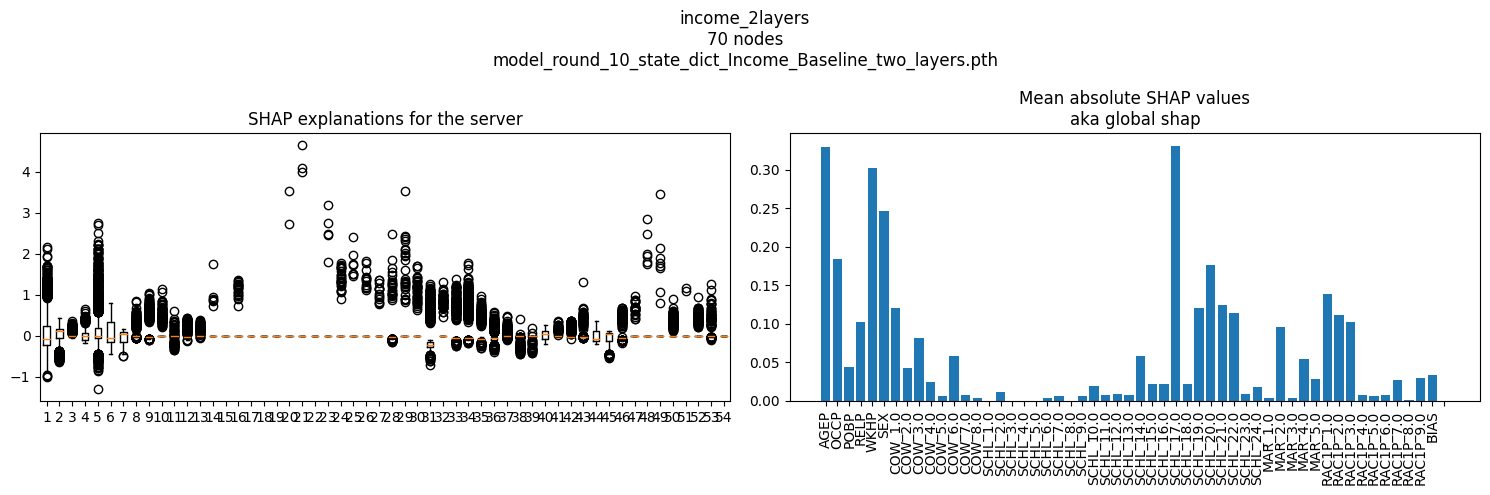

In [52]:
# plot it as barplots
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.title("SHAP explanations for the server")
plt.boxplot(audit_expl)
plt.subplot(1,2,2)
plt.title("Mean absolute SHAP values\naka global shap")
plt.xticks(np.arange(audit_expl.shape[1]),feat_names,rotation=90)
plt.bar(np.arange(audit_expl.shape[1]),np.mean(np.abs(audit_expl),axis=0))
# the sup title should be the name of the dataset, epsilon (if in [1,2]) the name of the model, the number of nodes
plt.suptitle(expl_name+"\n"+str(nc)+" nodes\n"+model_name+("" if epsilon not in [1,2] else " epsilon "+str(epsilon)))
plt.tight_layout()
plt.show()

In [53]:
folder
def load_shap_explanations_nb(node):
    file_path = os.path.sep.join(["shap3",
                            expl_name+"_shap_explanations_"+node+".npz"])
    if os.path.exists(file_path):
        return load_npz(file_path)
    else:
        return False
load_shap_explanations_nb(random_train_node)

In [54]:
audit_expl.shape

(2000, 54)

In [55]:

def load_representative_samples_nb(node):
    # can fail
    representative = load_representative(node)
    if isinstance(representative,bool):
        # always succed
        X_feat,y_labs = load_train_set(node,folder=folder)
        y_labs = np.eye(torch.max(y_labs)+1)[y_labs]
        X_feat = torch.Tensor(X_feat)
        y_labs = torch.Tensor(y_labs)
        print("representative exists?",representative)
        # load the data
        dataset = TensorDataset(X_feat,y_labs)
        rep_X_feat,rep_y_labs = get_representative_samples_france(dataset=dataset,samples_per_class=10)
        store_npz(f"./samples/{folder}_representative_samples_{node}.npz",X=rep_X_feat,y=rep_y_labs)
    else:
        print("found representatives for node",node,"!",end ='\t')
        rep_X_feat, rep_y_labs = representative["X"],representative["y"]
        print(rep_X_feat.shape,"samples")
    
    return {"X":rep_X_feat,"y":rep_y_labs}

for node in train_nodes:
    expl={}
    print(node)
    
    data_dict = load_representative_samples_nb(node)
    print(node,data_dict["X"].shape,data_dict["y"].shape)
    # instanciate the dataloader
    print("Use mean?",use_mean)
    if use_mean:
        data = TensorDataset(torch.Tensor(data_dict["X"].mean(axis=0).reshape(1,-1)),
                             torch.Tensor(np.median(data_dict["y"],axis=0).reshape(1,-1)))
    else:
        data = TensorDataset(torch.Tensor(data_dict["X"]),
                             torch.Tensor(data_dict["y"]))
    loader_bk_dt = DataLoader(data, batch_size=256,shuffle=False)
    
    # get the shap explanations using the load_shap_explanations_nb
    # if the result is an instance of bool, then it has to be computed
    # otherwise we are good
    node_exp =  load_shap_explanations_nb(node)
    if isinstance(node_exp,bool) or node_exp["shap"].shape != (audit_expl.shape):
        print("to recompute")
        #break
        if node_exp:
            print(node_exp["shap"].shape)
        node_exp = get_shap_explanations(model,
                    background_data_loader = loader_bk_dt,
                    explain_partition=loader_exp_dt)
        expl["shap"] = node_exp
    else:
        print("shap values for node ",node,"already computed!")
        expl["shap"] = node_exp["shap"]
    print(expl["shap"].shape)
# save the explanation
    if expl["shap"].shape == audit_expl.shape:
        store_npz(f"./shap3/{expl_name}_shap_explanations_{node}.npz",**expl)
    else:
        print("error")
        


10
found representatives for node 10 !	(40, 54) samples
10 (40, 54) (40, 2)
Use mean? False
shap values for node  10 already computed!
(2000, 54)
11
found representatives for node 11 !	(24, 54) samples
11 (24, 54) (24, 2)
Use mean? False
shap values for node  11 already computed!
(2000, 54)
12
found representatives for node 12 !	(36, 54) samples
12 (36, 54) (36, 2)
Use mean? False
shap values for node  12 already computed!
(2000, 54)
13
found representatives for node 13 !	(32, 54) samples
13 (32, 54) (32, 2)
Use mean? False
shap values for node  13 already computed!
(2000, 54)
14
found representatives for node 14 !	(32, 54) samples
14 (32, 54) (32, 2)
Use mean? False
shap values for node  14 already computed!
(2000, 54)
15
found representatives for node 15 !	(40, 54) samples
15 (40, 54) (40, 2)
Use mean? False
shap values for node  15 already computed!
(2000, 54)
16
found representatives for node 16 !	(20, 54) samples
16 (20, 54) (20, 2)
Use mean? False
shap values for node  16 already

In [56]:
   
all_expl = []
for node in train_nodes:
    out = load_shap_explanations_nb(node)
    if isinstance(out,bool):
        print("no explanation for node",node)
    else:
        all_expl.append(out["shap"])
all_expl = np.array(all_expl)
print(all_expl.shape)

(41, 2000, 54)


In [57]:
np.abs((audit_expl-np.mean(all_expl,0))).mean()

0.020996644228076962

In [58]:
all_expl[0]

array([[-0.21860803, -0.33970563,  0.15512017, ...,  0.        ,
        -0.07387812,  0.        ],
       [-0.54135282, -0.13738372,  0.0064243 , ...,  0.        ,
        -0.11300345,  0.        ],
       [-0.62295348, -0.3653253 , -0.01161989, ...,  0.        ,
        -0.07195868,  0.        ],
       ...,
       [-0.5538278 ,  0.05528819, -0.01296464, ...,  0.        ,
        -0.10687528,  0.        ],
       [-0.52060029, -0.50698303,  0.12208936, ...,  0.        ,
        -0.07634097,  0.        ],
       [-0.35633936,  0.09917479, -0.01479575, ...,  0.        ,
        -0.08530925,  0.        ]])

In [59]:
for j,e in enumerate(np.round(audit_expl[:3,:],5)):
    print("explanation:","\t".join([str(np.round(el,4)) for el in e]))
    print("client 1:   ","\t".join([str(np.round(el,4)) for el in all_expl[1,j,:]]))

explanation: -0.0421	-0.3303	0.1756	-0.0833	-0.0316	-0.0589	-0.0439	-0.0068	-0.017	0.0	0.0	0.4333	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	-0.0269	0.0	0.0	-0.1732	0.0	-0.0445	-0.0328	-0.0514	-0.053	0.0606	0.0124	0.0	0.0494	0.0	0.1306	-0.0112	-0.0661	0.0376	-0.0378	0.0	0.0	0.0	0.0	0.0	0.0	-0.015	0.0
client 1:    -0.1238	-0.3693	0.1538	-0.0966	-0.1935	-0.1206	-0.0785	-0.0054	0.0	-0.0264	0.0105	0.4889	-0.0151	0.0	0.0	-0.0433	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	-0.0963	-0.0596	-0.0646	-0.0538	-0.0695	-0.0546	0.0984	0.0146	0.0	0.0069	0.0	0.1263	-0.0242	-0.0214	0.0393	0.0	-0.0269	0.0	0.0	-0.0028	0.0	-0.0073	-0.0109	0.0
explanation: -0.2725	-0.1013	0.0266	0.2468	-0.0174	-0.0946	0.0413	-0.0188	-0.0206	0.0	0.0	-0.0242	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	-0.0324	0.0	0.0	-0.2036	0.0	0.6446	-0.0411	-0.0727	-0.06	0.0	0.0154	0.0	-0.0212	0.0	0.16	-0.0186	-0.0729	-0.1372	0.394	0.0	0.0	0.0	0.0	0.0	0.0	-0.0167	0.0
client 1:    -0.4019	-0.146

In [60]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [61]:
dt_name = "adult"

computing $ShapGap_{L2}$ distance


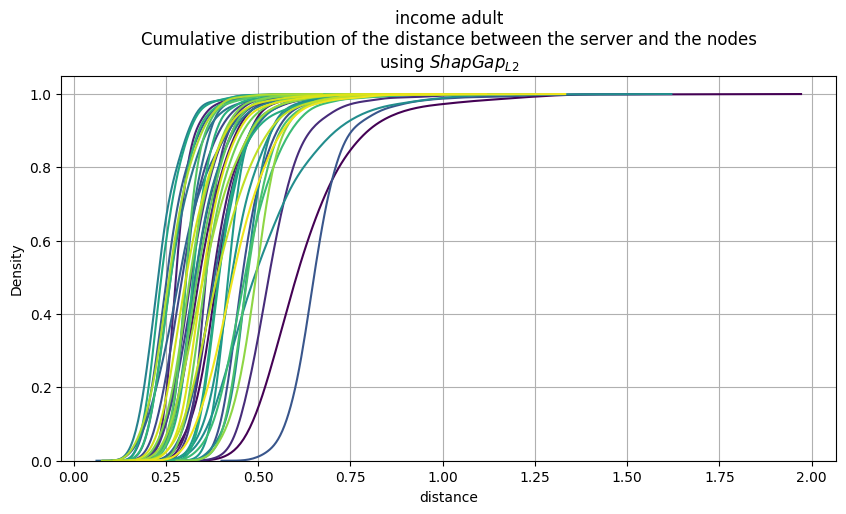

computing $ShapGap_{Kendall}$ similarity


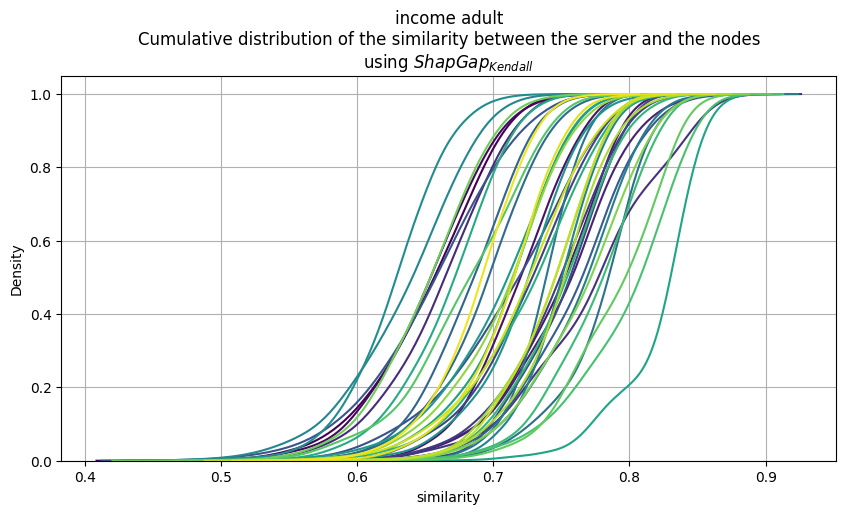

computing $ShapGap_{CosSim}$ similarity


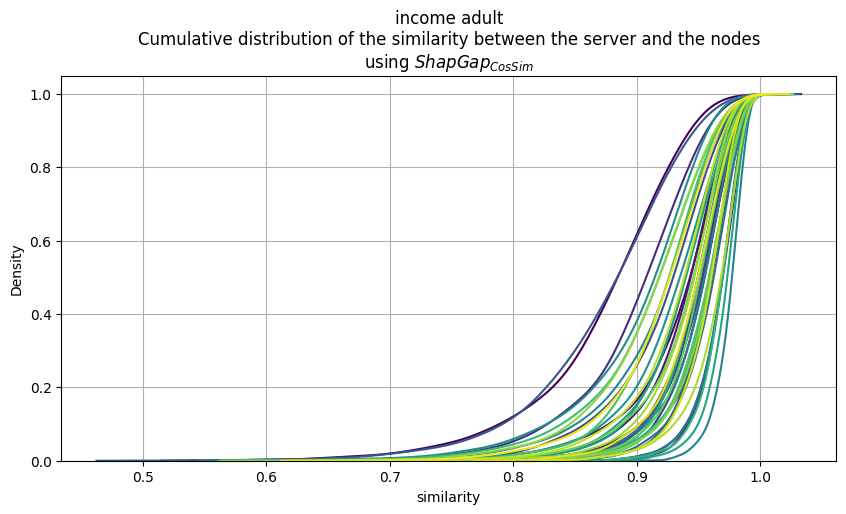

In [62]:
import seaborn as sns
# compute the difference between the shap values of the server and the average of the nodes
# then plot the kde plot of the differences
for j,metr in enumerate(["$ShapGap_{L2}$","$ShapGap_{Kendall}$","$ShapGap_{CosSim}$"]):
    plt.figure(figsize=(10,5))
    comparing_f = [compare_heatmaps_Frobenius,compare_heatmaps_kendalltau,compare_heatmaps_cosinesim][j]
    metric_d = ["distance","similarity","similarity"][j]
    print("computing",metr,metric_d)
    for jj,explanation_c in enumerate(all_expl):
        # select color from the hsv color map
        color = plt.cm.viridis(jj/len(all_expl))
        res = comparing_f(explanation_c,audit_expl)
        #res=res.sum(1).reshape(-1,1)
        #print(res.max(),res.mean(),res.std(),res.shape)
        #print(res.shape)
        sns.kdeplot(res,cumulative=True,color=color)
    plt.title(folder+" "+dt_name+"\n""Cumulative distribution of the "+metric_d+" between the server and the nodes\nusing "+metr)
    plt.xlabel(metric_d)
    plt.grid(True)
    # save the image
    plt.savefig(folder+"_"+expl_name+"_cumulative_"+metr+".pdf")
    plt.show()
    plt.clf()
    plt.close()


# FLEXAI 
## Explanation as a service

In [63]:

print(feat_names)

['AGEP', 'OCCP', 'POBP', 'RELP', 'WKHP', 'SEX', 'COW_1.0', 'COW_2.0', 'COW_3.0', 'COW_4.0', 'COW_5.0', 'COW_6.0', 'COW_7.0', 'COW_8.0', 'SCHL_1.0', 'SCHL_2.0', 'SCHL_3.0', 'SCHL_4.0', 'SCHL_5.0', 'SCHL_6.0', 'SCHL_7.0', 'SCHL_8.0', 'SCHL_9.0', 'SCHL_10.0', 'SCHL_11.0', 'SCHL_12.0', 'SCHL_13.0', 'SCHL_14.0', 'SCHL_15.0', 'SCHL_16.0', 'SCHL_17.0', 'SCHL_18.0', 'SCHL_19.0', 'SCHL_20.0', 'SCHL_21.0', 'SCHL_22.0', 'SCHL_23.0', 'SCHL_24.0', 'MAR_1.0', 'MAR_2.0', 'MAR_3.0', 'MAR_4.0', 'MAR_5.0', 'RAC1P_1.0', 'RAC1P_2.0', 'RAC1P_3.0', 'RAC1P_4.0', 'RAC1P_5.0', 'RAC1P_6.0', 'RAC1P_7.0', 'RAC1P_8.0', 'RAC1P_9.0', 'BIAS', '']


In [64]:
exps = [folder][-1:]
focus = [folder]
exps

['income']

In [65]:
all_shap_dict = {exp : {"Server":audit_expl,"Clients":all_expl,
                        "E_hat":all_expl.mean(axis=0)} for exp in exps}

for exp in exps:
    # checkfor nans
    #print(all_shap_dict[exp]["Clients"]!=all_shap_dict[exp]["Clients"]).any()
    all_shap_dict[exp]["E_weighted"] = np.average(all_shap_dict[exp]["Clients"],axis=0,weights=[get_f1(exp,node) for node in train_nodes])

    all_shap_dict[exp]["E_f1_macro"] = np.average(all_shap_dict[exp]["Clients"],axis=0,weights=[get_f1(exp,node,macro=True) for node in train_nodes])

    all_shap_dict[exp]["Delta"] = all_shap_dict[exp]["Server"]-all_shap_dict[exp]["E_hat"]



In [66]:
folder

'income'

In [67]:
train_nodes

['10',
 '11',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '20',
 '21',
 '22',
 '23',
 '24',
 '25',
 '26',
 '27',
 '28',
 '29',
 '30',
 '31',
 '32',
 '33',
 '34',
 '35',
 '36',
 '37',
 '38',
 '39',
 '40',
 '41',
 '42',
 '43',
 '44',
 '45',
 '46',
 '47',
 '48',
 '49',
 '50']

In [68]:
exp, focus

('income', ['income'])

(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients


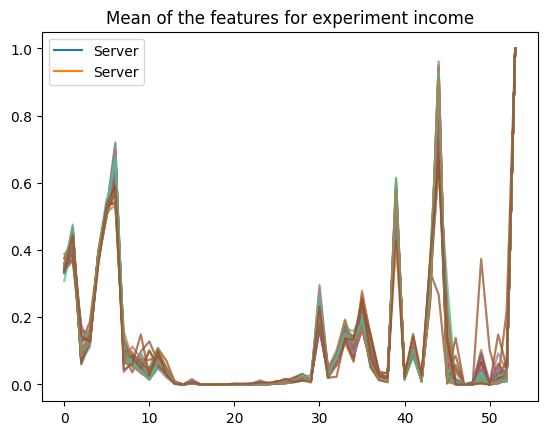

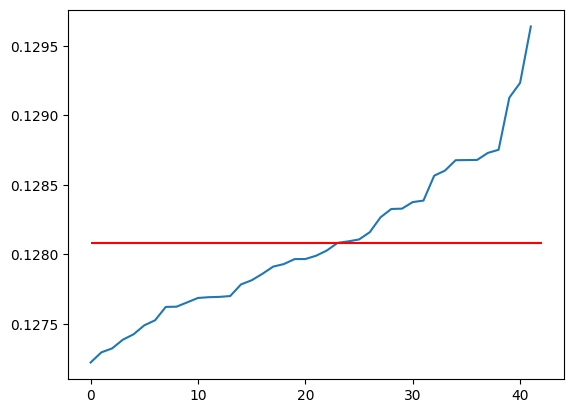

(2000, 2)
Server
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients
Clients


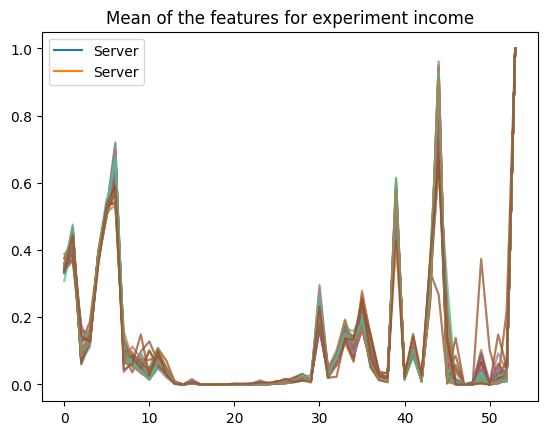

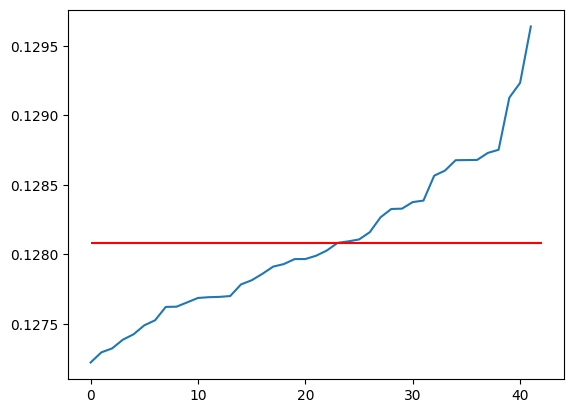

In [85]:
all_base_values = {exp:{} for exp in focus}
def check_compute_faithfulness(neural_model,exp, all_shap_values_dict, base_value,te_set,local_mean=False,
store_base_values={},compute=True):

    shap_values_dict = all_shap_values_dict[exp]
    model = aix_model(neural_model)
    num_clients = len(shap_values_dict["Clients"])
    # for every class get the indices of the samples so that we can return the indexes of the samples of that class
    class_idxs = []
    num_classes = te_set.tensors[1].shape[1]
    # now substitute the tensors[1] with its argmax
    ordinal_targets = te_set.tensors[1].argmax(axis=1)
    for i in range(num_classes):
        class_idxs.append(np.where(ordinal_targets == i)[0])
    x = te_set.tensors[0].numpy()
    
    faith_dict = {"Server": [], "Clients": []}

    activations = model.predict_proba(x)
    print(activations.shape)
    all_base_values = []
    for client_id in range(num_clients + 1):
        if client_id == 0:
            key = "Server"
            coefs = shap_values_dict[key]
        else:
            key = "Clients"
            coefs = shap_values_dict[key][client_id - 1]

        
        faits = []
        num_samples = 2000
        # load the train data of the node
        if client_id == 0:
            all_X_feat, all_y_labs = np.array([]),np.array([])
            for noed in train_nodes:
                X_feat, y_labs = load_train_set(node=noed,folder=folder)
                all_X_feat = np.concatenate([all_X_feat,X_feat]) if all_X_feat.size else X_feat
                all_y_labs = np.concatenate([all_y_labs,y_labs]) if all_y_labs.size else y_labs

            all_X_feat = torch.Tensor(all_X_feat)
            data = all_X_feat,42
        else:
            data = load_train_set(node=train_nodes[client_id - 1],folder=folder)
        # compute the mean of the train data

        mean = data[0].mean(axis=0)
        # compute the mean of the means
        base_value = data[0].mean()
        all_base_values.append(base_value)
        #print("mean",mean)
        #print("base value",base_value)
        if key != "Server":
            plt.plot(mean,alpha=0.5)
        else:
            plt.plot(mean,label=key)
        print(key)
        
        for sample, fi in zip(x[:num_samples], coefs[:num_samples]):
            if compute :
                faith_m = faithfulness_metric(model=model,
                                          x=sample,
                                          coefs=fi,
                                          base=(mean if local_mean else base_value * np.ones(shape=fi.shape[0])),
                                          )
            
                faits.append(faith_m)
        if local_mean:
            store_base_values[exp][100] = mean
        else:
            store_base_values[exp][1000] = base_value * np.ones(shape=fi.shape[0])
        
        faith_dict[key].append(np.array(faits))
        if key != "Server":
            plt.plot(mean,alpha=0.5)
        else:
            plt.plot(mean,label=key)
    plt.title("Mean of the features for experiment "+str(exp))
    plt.legend()
    plt.show()
    plt.plot(sorted(all_base_values))
    plt.hlines(all_base_values[0],0,len(all_base_values),color="red")
    plt.show()

    return class_idxs,faith_dict,activations

_,new_f_local_mean,_ = check_compute_faithfulness(model,exp,all_shap_dict,0,exp_dt,local_mean=False,store_base_values=all_base_values,compute=False)
_, new_f_mean_mean,_ = check_compute_faithfulness(model,exp,all_shap_dict,0,exp_dt,local_mean=True,store_base_values=all_base_values,compute=False)

In [176]:

#result = compute_faithfulness(model,folder, all_shap_dict, 0,exp_dt)

In [86]:
dt_name = "adult_"+str(epsilon)
dt_name+"_"+folder,model_name,model_path
name_dataset = "Income"

In [87]:
for k in all_faith_dict[exp].keys():
    print(k)
    print(len(all_faith_dict[exp][k]["Server"]))

-0.5
1
-0.2
1
0.001
1
0.2
1
0.5
1
100.0
1
1000.0
1


### Uncomment the next cell to create and save the actual files

In [70]:
'''
base_values = sorted([-0.5,0.5,0.001,0.2,-0.2,])
all_faith_dict = {}
indexes_per_calss = {}
activations_of_models = {}

for exp in focus:
    print("Experiment:",exp)
    
    indexes, results_dict,activas = get_exps_faiths(neural_model=model,
                                                    exp = exp,
                                                    base_values = base_values,
                                                    all_shap_values_dict = all_shap_dict,
                                                    te_set = exp_dt)
    all_faith_dict[exp] = results_dict
    indexes_per_calss[exp] = indexes
    activations_of_models[exp] = activas

'''

'\nbase_values = sorted([-0.5,0.5,0.001,0.2,-0.2,])\nall_faith_dict = {}\nindexes_per_calss = {}\nactivations_of_models = {}\n\nfor exp in focus:\n    print("Experiment:",exp)\n    \n    indexes, results_dict,activas = get_exps_faiths(neural_model=model,\n                                                    exp = exp,\n                                                    base_values = base_values,\n                                                    all_shap_values_dict = all_shap_dict,\n                                                    te_set = exp_dt)\n    all_faith_dict[exp] = results_dict\n    indexes_per_calss[exp] = indexes\n    activations_of_models[exp] = activas\n\n'

In [88]:
'''all_faith_dict[exp][100] = {}
all_faith_dict[exp][1000] = {}

all_faith_dict[exp][100]["Clients"] = np.array(new_f_local_mean["Clients"])
all_faith_dict[exp][1000]["Clients"] = np.array(new_f_mean_mean["Clients"])

all_faith_dict[exp][100]["Server"] = np.array(new_f_local_mean["Server"])
all_faith_dict[exp][1000]["Server"] = np.array(new_f_mean_mean["Server"])'''

all_faith_dict[exp].keys()


dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100.0, 1000.0])

In [79]:
'''


import json
with open(dt_name+"_"+folder+"_all_faith_dict.json","w+") as f:
    # convert the numpy arrays to lists
    all_faith_dict_list = {k:
                            {base_value:
                                {k2:list([list(values) for values in v2])
                                for k2,v2 in serverclient.items()}
                            for base_value,serverclient in v.items()}
                        for k,v in all_faith_dict.items()}
    json.dump(all_faith_dict_list,f)
with open(dt_name+"_"+folder+"_indexes_per_calss.json","w+") as f:
    indexes_per_calss_list = {k:[(v1.tolist() if not isinstance(v1,list) else v1) for v1 in v] for k,v in indexes_per_calss.items()}
    json.dump(indexes_per_calss_list,f)

with open(dt_name+"_"+folder+"_activations_of_models.json","w+") as f:
    activations_of_models_list = {k:{k1:(v1.tolist() if not isinstance(v1,list) else v1) for k1,v1 in v.items()} for k,v in activations_of_models.items()}
    json.dump(activations_of_models_list,f)
'''

In [89]:
expl_name

'income_2layers'

In [90]:
folder,dt_name

('income', 'adult_100')

#### Load the files

In [91]:
import json

with open(dt_name+"_"+folder+"_indexes_per_calss.json", "r") as f:
    # print the date of the last modification
    indexes_per_calss_list = json.load(f)
    print("last modification",time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(os.path.getmtime(dt_name+"_"+folder+"_indexes_per_calss.json"))))

indexes_per_calss = {k: np.array([np.array(v1) for v1 in v]) for k, v in indexes_per_calss_list.items()}
with open(dt_name+"_"+folder+"_activations_of_models.json", "r") as f:
    activations_of_models_list = json.load(f)
    print("last modification",time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(os.path.getmtime(dt_name+"_"+folder+"_activations_of_models.json"))))



activations_of_models = {k: {float(k1): np.array(v1) for k1, v1 in v.items()} for k, v in activations_of_models_list.items()}

# Now you have loaded dictionaries: all_faith_dict, indexes_per_calss, activations_of_models
# Convert the lists back to NumPy arrays
with open(dt_name+"_"+folder+"_all_faith_dict.json", "r") as f:
    all_faith_dict_list = json.load(f)
    print("last modification",time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(os.path.getmtime(dt_name+"_"+folder+"_all_faith_dict.json"))))
all_faith_dict = {k:
                    {float(base_value):
                        {k2:np.array([np.array(values) for values in v2])
                        for k2,v2 in serverclient.items()}
                    for base_value,serverclient in v.items()}
                for k,v in all_faith_dict_list.items()}
all_shap_dict[list(all_shap_dict.keys())[0]].keys(),all_faith_dict["income"].keys()


last modification 2024-11-25 14:45:42
last modification 2024-11-25 14:45:42


Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


last modification 2024-11-25 14:45:42


(dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta']),
 dict_keys([-0.5, -0.2, 0.001, 0.2, 0.5, 100.0, 1000.0]))

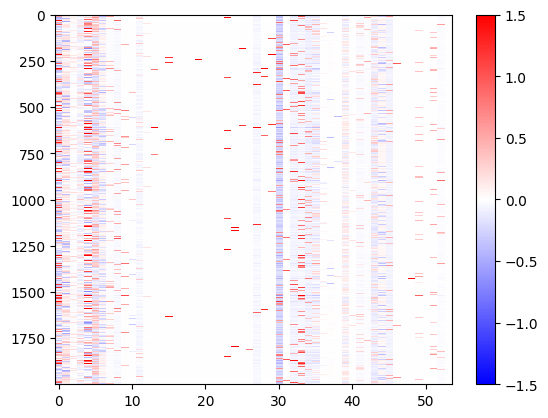

In [92]:
plt.imshow(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"],aspect="auto",cmap="bwr",interpolation="none",
           vmin=-1.5,vmax=1.5)
plt.colorbar()

Text(0.5, 1.0, 'Shap values of the server, the average of the nodes and a random node')

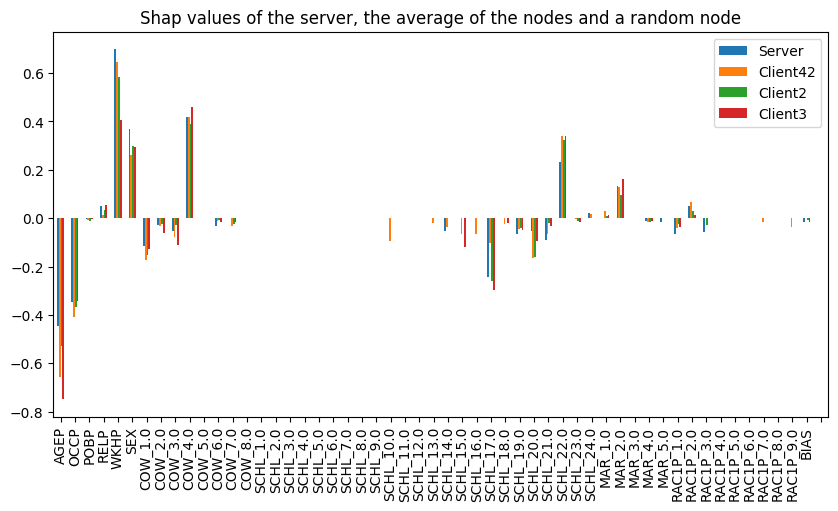

In [93]:
# take a random sample
random_sample = np.random.choice(np.arange(len(exp_set["X"])),1)[0]
random_sample
# add the explanation of the random sample of the server of the E_hat and of the random node to a dataframe and plot the bars relative to the explanation values
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.DataFrame({"Server":all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                     #"E_hat":all_shap_dict[list(all_shap_dict.keys())[0]]["E_hat"][random_sample],
                     "Client"+random_train_node:all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][train_nodes.index(random_train_node)][random_sample],
                     "Client2":all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][train_nodes.index(random_train_node)+1][random_sample],
                     "Client3":all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][train_nodes.index(random_train_node)+2][random_sample]}
                     ,index=feat_names)
df.plot(kind="bar",figsize=(10,5))
plt.title("Shap values of the server, the average of the nodes and a random node")



In [77]:
'''# let's take into example the first 3 features
#we now take the explanation of the server and the explanation of 3 random nodes
# we will check if the explanation of the server can be obtained by a linear combination of the explanation of the node(s) to do so we "fit" a linear regression model (obtained by a division) to the explanation of the server and the explanation of the node(s)
random_train_node = np.random.choice(train_nodes)
brandom_samples = np.random.choice(np.arange(len(exp_set["X"])),10)
nsampl_ = 500
arr_coef = []
for random_sample in brandom_samples:
    coefs = all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample]/(all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][train_nodes.index(random_train_node)][random_sample]+0.01)
    arr_coef.append(coefs)

plt.boxplot(np.array(arr_coef))
plt.show()
plt.imshow(np.array(arr_coef),aspect="auto",cmap="Reds",interpolation="none")
plt.colorbar()
plt.show()

coefs = np.median(arr_coef,0)
# now use this coef to multiply the explanation of the node for other 5 samples and compare the result with the explanation of the server
# if the result is close to the explanation of the server then the explanation of the server can be obtained by a linear combination of the explanation of the node
# the closer the better
random_samples = np.random.choice(np.arange(len(exp_set["X"])),nsampl_,replace=False)
# get the explanations
node_expl = all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][train_nodes.index(random_train_node)][random_samples]
# multiply the explanation of the node by the coef
comparable_serv_expl = node_expl*coefs
# get the explanation of the server
server_expl = all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_samples]
# compute the difference
diff = abs(server_expl-comparable_serv_expl)
# plot the difference
fig,ax = plt.subplots(ncols=2,nrows=1,figsize=(15,5))
imm = ax[0].imshow(diff,aspect="auto",cmap="Reds",interpolation="none")
# add the colorbar
fig.colorbar(imm,ax=ax[0])
# add the title 
titl = ("base sample "+str(brandom_samples)+"\nDifference between the server and "+str(nsampl_)+" node explanations multiplied by the coef for the node "+str(random_train_node))
ax[0].set_title(titl)
# now plot the barplot of the difference
df = pd.DataFrame(diff.sum(0),index=feat_names,columns=["Difference (sum)"])
df.plot(kind="bar",ax=ax[1])

'''

'# let\'s take into example the first 3 features\n#we now take the explanation of the server and the explanation of 3 random nodes\n# we will check if the explanation of the server can be obtained by a linear combination of the explanation of the node(s) to do so we "fit" a linear regression model (obtained by a division) to the explanation of the server and the explanation of the node(s)\nrandom_train_node = np.random.choice(train_nodes)\nbrandom_samples = np.random.choice(np.arange(len(exp_set["X"])),10)\nnsampl_ = 500\narr_coef = []\nfor random_sample in brandom_samples:\n    coefs = all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample]/(all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][train_nodes.index(random_train_node)][random_sample]+0.01)\n    arr_coef.append(coefs)\n\nplt.boxplot(np.array(arr_coef))\nplt.show()\nplt.imshow(np.array(arr_coef),aspect="auto",cmap="Reds",interpolation="none")\nplt.colorbar()\nplt.show()\n\ncoefs = np.median(arr_coef,0)\n# no

In [94]:
import matplotlib.ticker as ticker

In [95]:
for k,v in all_faith_dict[folder].items():
    print(k)
    #QUIQUOQUA

-0.5
-0.2
0.001
0.2
0.5
100.0
1000.0


In [96]:
all_shap_dict.keys(),folder

(dict_keys(['income']), 'income')

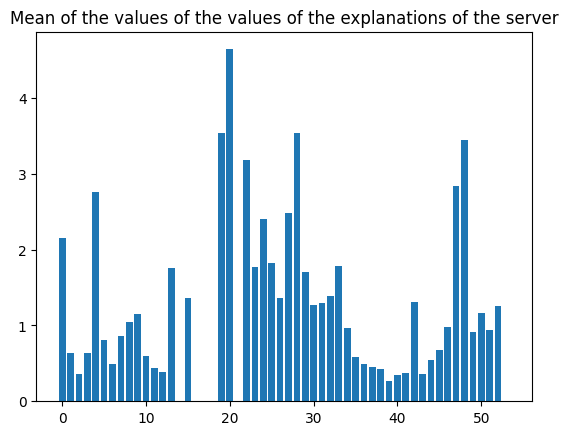

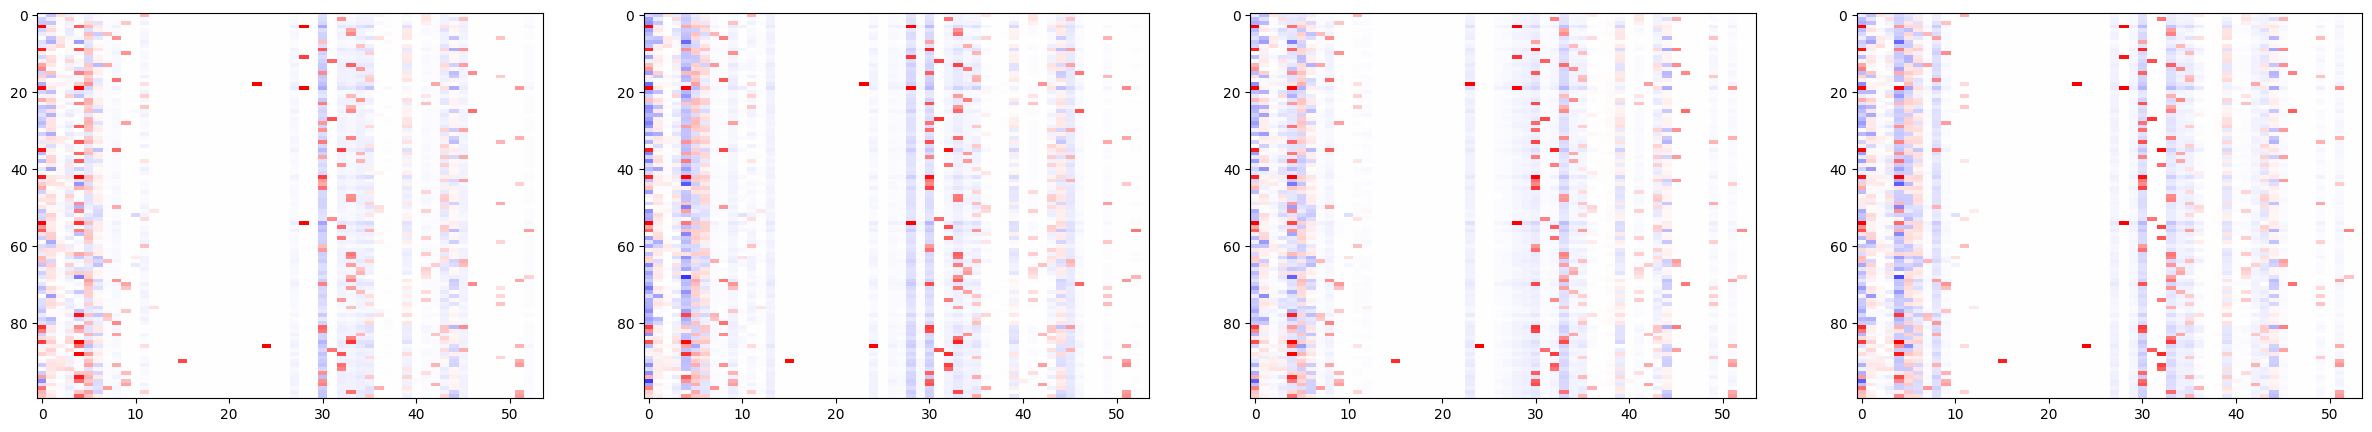

In [97]:
# 
plt.title("Mean of the values of the values of the explanations of the server")
plt.bar(np.arange(all_shap_dict[folder]["Server"].shape[1]),abs(all_shap_dict[folder]["Server"]).max(0))#.keys()
plt.show()
#plt.boxplot(all_shap_dict['models_150_nodes']["Server"])#.keys()

fig,ax = plt.subplots(nrows=1,ncols=4,figsize=(30,5))
ax = ax.flatten()
ax[0].imshow(           all_shap_dict[folder]["Server"][:100,:],interpolation='none',cmap='bwr', rasterized=True,aspect='auto',vmin=-1.5,vmax=1.5)
for j,i in enumerate([5,32,21]):
    ax[1+j].imshow(     all_shap_dict[folder]["Clients"][i][:100,:],interpolation='none',cmap='bwr', rasterized=True,aspect='auto',vmin=-1.5,vmax=1.5)
    #ax[j].axis('auto')
#plt.show()

In [98]:
# just for cheking select 10 random samples
random_samples = np.random.choice(np.arange(len(all_shap_dict[folder]["Server"])),2000,replace=False)
# for every node in the train nodes, select the same 10 random samples and compute the difference with the server
# then do the mean 
# and print them
similars = []
for j,node in enumerate(train_nodes):
    node_shap = all_shap_dict[folder]["Clients"][j]
    diffs = np.abs(node_shap[random_samples]-all_shap_dict[folder]["Server"][random_samples])
    if np.round(diffs.std(0),2).mean()<0.01:
        #print("node",node,"is very similar to the server")
        similars.append(node)
    #print()

print(similars)
len(similars)

['22', '34', '46']


3

#


Faithfulnesses for base value -0.5
Server 0.07922534544924335 0.3052480521887053 (1, 2000)

Faithfulnesses for base value -0.2
Server 0.19207585952691725 0.3991705891228799 (1, 2000)

Faithfulnesses for base value 0.001
Server 0.2725402266648351 0.48413369515036947 (1, 2000)

Faithfulnesses for base value 0.2
Server 0.33132831612119434 0.5303490280175971 (1, 2000)

Faithfulnesses for base value 0.5
Server 0.3552750809152765 0.35940451561308623 (1, 2000)

Faithfulnesses for base value 100.0
Server 0.30760516411576305 0.5336949799583605 (1, 2000)

Faithfulnesses for base value 1000.0
Server 0.4204465499739043 0.7722689557240391 (1, 2000)


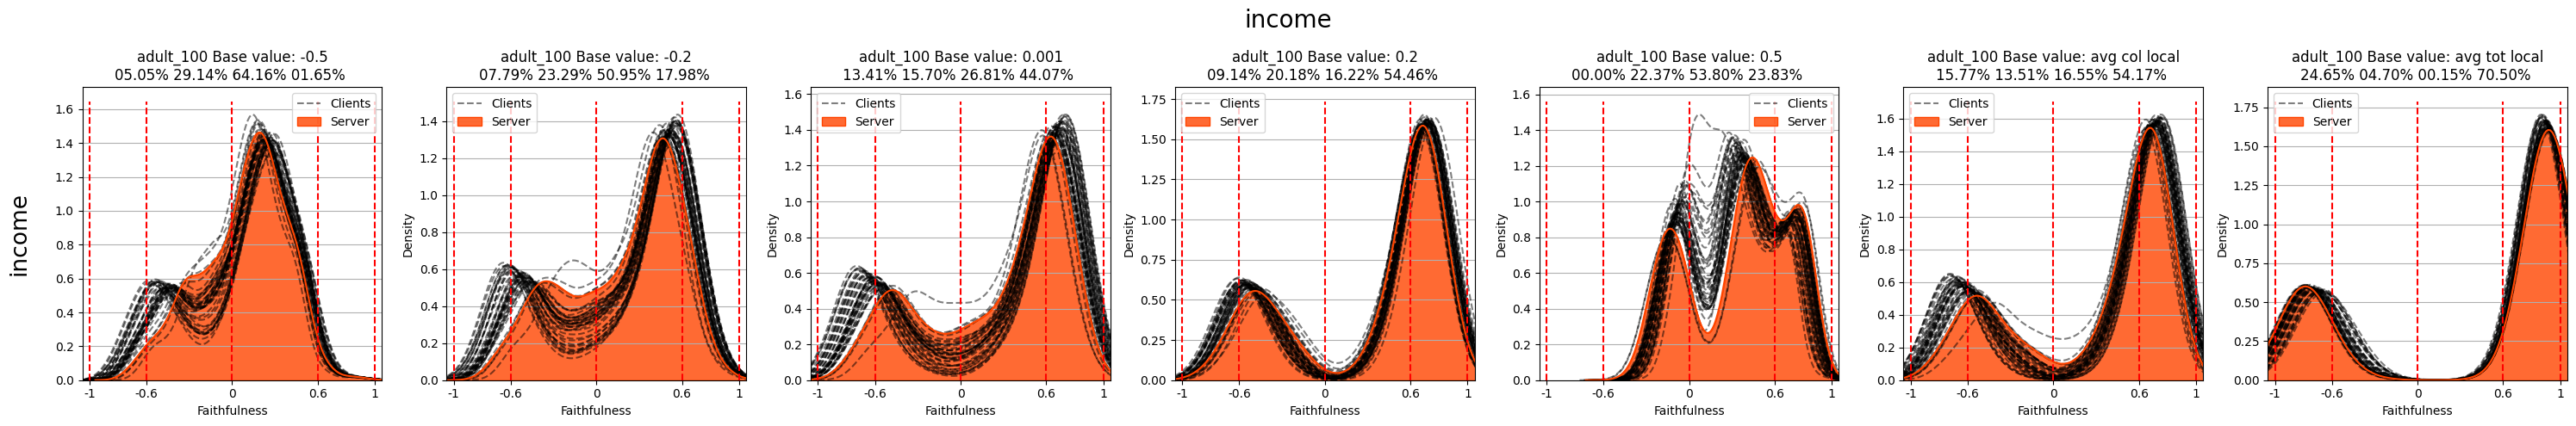

In [99]:
# the fill color is based soley on the dataset, orange for dry bean, blue for dutch, red for adult, light blue for diamonds



n_bvs = len(sorted(all_faith_dict[exps[0]].keys()))
fig,ax = plt.subplots(1,n_bvs,figsize=(30,5))
ax = ax.reshape(-1)
o_i = 0

text_percs = []
for exp in [exp]:
        
        # create the figure with as many subplots as the number of base values
        # then plot the distribution of the faithfulnesses of all the nodes with a low opacity
        # then plot the faithfulness of the server with a higher opacity
        base_values = sorted(all_faith_dict[exp].keys())
        for j,bv in enumerate(base_values):
                j+=n_bvs*o_i
                # get the faithfulnesses
                ff = all_faith_dict[exp][bv]
                print()
                # get the indexes of the classes
                indexes = indexes_per_calss[exp]
                # get the activations of the model
                activas = activations_of_models
                # plot the faithfulnesses
                print("Faithfulnesses for base value",bv)
                print("Server",np.array(ff["Server"]).mean(),ff["Server"].std(),ff["Server"].shape)
                for i in range(len(ff["Clients"])):
                    # plot the faithfulness of the nodes
                    if i == 0:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.5,ls="--",color="black",cumulative=False,label="Clients")
                    else:
                        sns.kdeplot(ff["Clients"][i],ax=ax[j],fill=False,alpha=0.5,ls="--",color="black",cumulative=False)
                # plot the faithfulness of the server
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],label="Server",fill=True,alpha=0.8,cumulative=False,color="orangered")
                sns.kdeplot(ff["Server"].reshape(-1),ax=ax[j],fill=False,alpha=1,cumulative=False,color="orangered")
                trs = [-0.6,0,0.6]
                trs = [-1]+trs+[1]
                percs = []
                title_addition = ''
                for i in range(len(trs) - 1):
                    lower = trs[i]
                    upper = trs[i+1]
                    pperc = ((ff["Clients"][:] > lower) & (ff["Clients"][:] <= upper)).mean()
                    perc = np.round(pperc * 100, 2)
                    percs.append(perc)
                    title_addition += f"{perc:05.2f}% "

                ylim = ax[j].get_ylim()

                ax[j].vlines(trs,0,ylim[1],colors="red",linestyles="--")

                # set the xticks at -1,-0.6,0,0.6,1
                ax[j].set_xticks(trs)

                # set the xticks labels
                ax[j].set_xticklabels([str(t) for t in trs])
                # add to the title the average percentage of client's explanations that are less than -0.6

                if bv == 100:
                    bv = 'avg col local'
                if bv == 1000:
                    bv = 'avg tot local'
                ax[j].set_title(f"{dt_name} Base value: {bv}\n{title_addition}")
                ax[j].set_xlabel("Faithfulness")
                ax[j].set_ylabel("Density") 
                # fix the x limits
                ax[j].set_xlim(-1.05,1.05)
                # set the y grid
                ax[j].grid(axis="y")

                # plot vertical lines at -0.6, 0 and 0.6
                # if the subplot is the first of the row, set the ylabel as the p and d
                if j%len(base_values) == 0:
                    ax[j].set_ylabel(exp,rotation=90,labelpad=20,fontsize=19)
                # if the subplot is the first raw set the legend
                if j < len(base_values):
                    ax[j].legend()
        o_i+=1 
plt.suptitle("income",fontsize=20)
plt.tight_layout()
plt.show()

gt0 0.6575
gt0 0.687
gt0 0.7155
gt0 0.707
gt0 0.7405
gt0 0.7085
gt0 0.7065
['class 1\nsupp:[   3    5    7 ... 1996 1997 1999]', 'class 2\nsupp:[   0    1    2    4    6    8   10   13   16   20   26   27   31   34\n   38   40   41   43   46   50   52   57   59   63   64   65   68   69\n   72   73   74   76   77   79   80  100  103  104  105  107  108  109\n  112  114  119  126  128  134  136  137  139  140  143  146  150  151\n  153  154  155  158  160  165  170  171  174  176  178  179  180  185\n  188  190  191  192  196  198  199  201  202  204  208  209  210  212\n  225  226  227  228  229  230  233  234  237  238  239  241  242  248\n  250  251  253  257  258  263  264  268  270  273  279  280  283  284\n  288  292  293  298  305  309  312  317  318  319  322  326  329  331\n  334  336  338  340  344  345  349  350  359  363  365  366  367  370\n  371  374  375  379  387  389  390  391  393  394  395  396  397  398\n  403  405  406  408  412  415  420  425  439  440  444  445  44

Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.


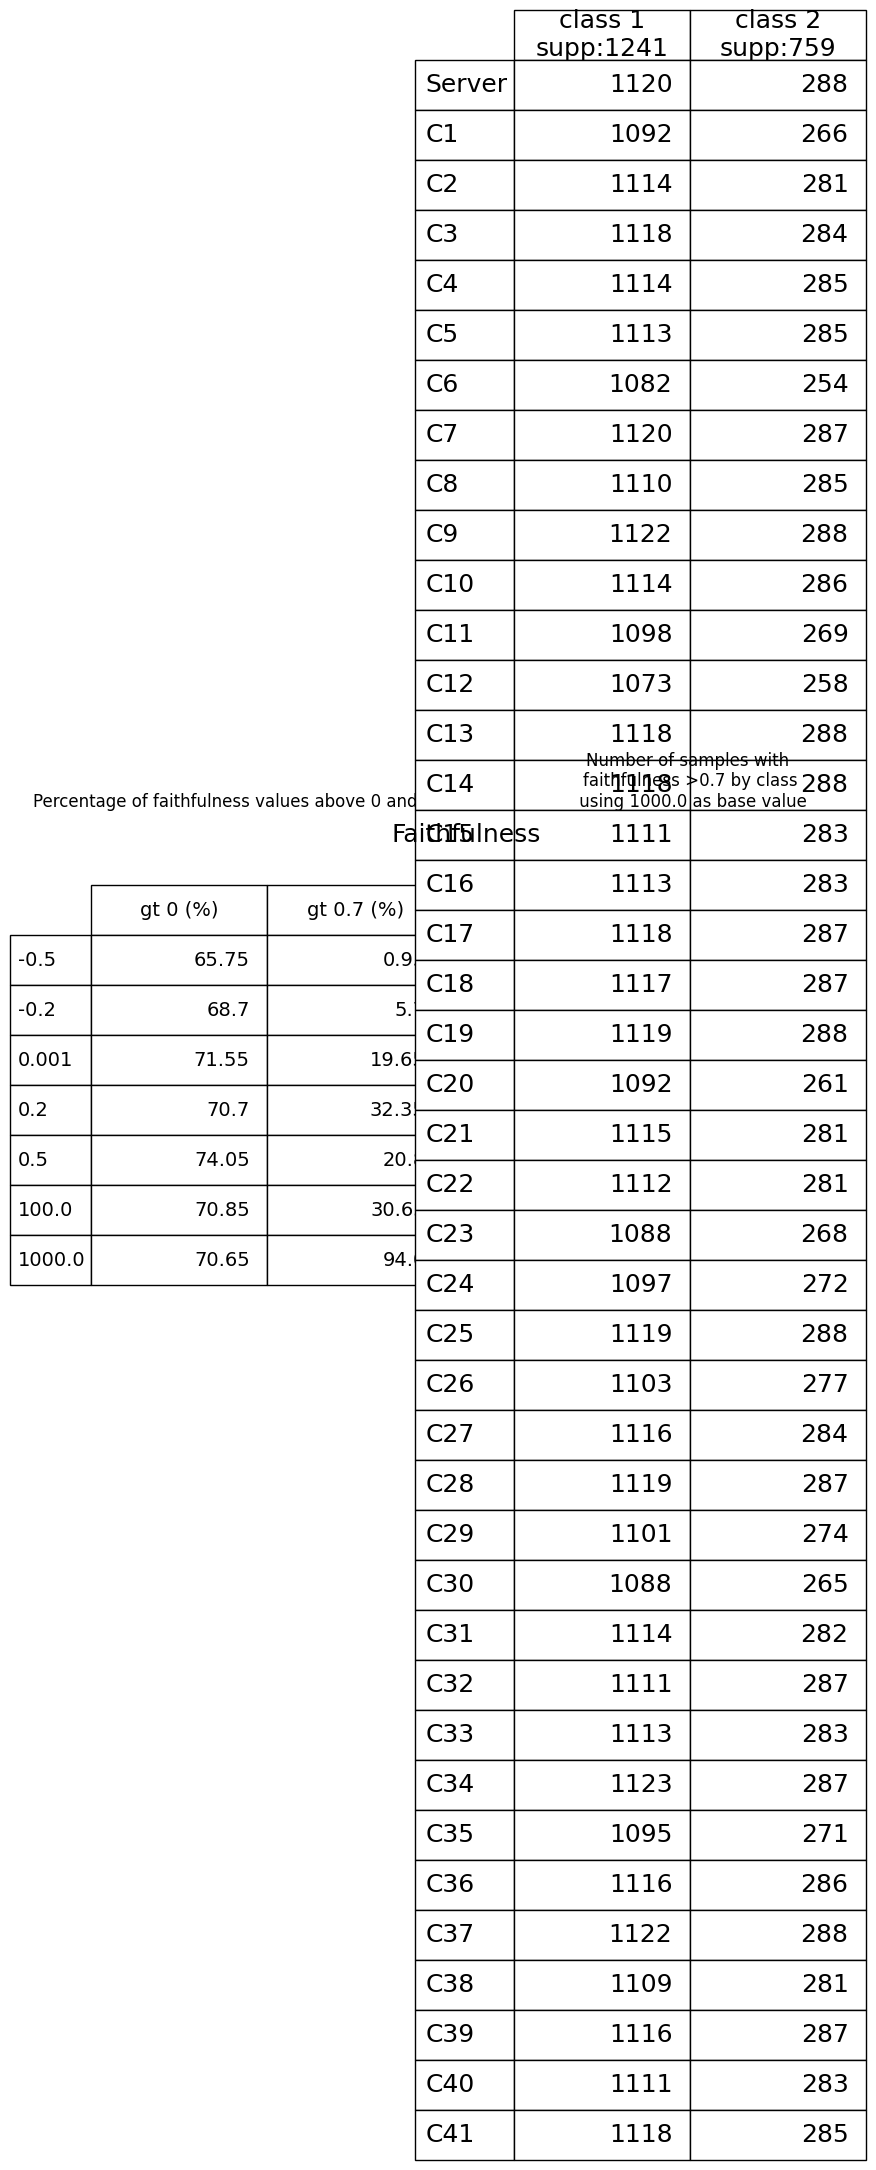

In [100]:
results_dict = all_faith_dict[folder]
indexes = indexes_per_calss[folder]
vals,m_faits = plot_table(results_dict,class_idxs=indexes,threshold=.7)


In [101]:
m_faits

array([[0.6575, 0.0095],
       [0.687 , 0.057 ],
       [0.7155, 0.1965],
       [0.707 , 0.3235],
       [0.7405, 0.208 ],
       [0.7085, 0.3065],
       [0.7065, 0.94  ]])

In [102]:
b_v = 1000

ShapGap L2: 0.46156191289960463
ShapGap Kendall: 0.6730157284952959
ShapGap Cosine: 0.9157706319846028
ShapGap Spearman: 0.7706303818751025


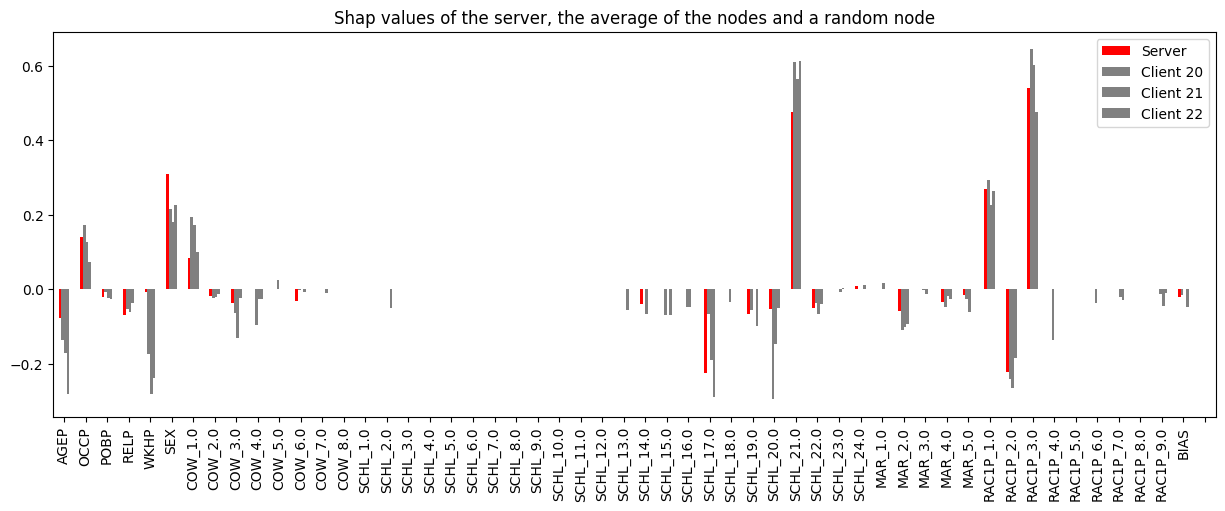

0.3741394108947135
0.13216773467138404
0.06875250153825602


In [103]:
# take a random sample
random_sample = np.random.choice(np.arange(len(exp_set["X"])),1)[0]
random_sample
# add the explanation of the random sample of the server of the E_hat and of the random node to a dataframe and plot the bars relative to the explanation values
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
random_train_node = np.random.choice(train_nodes)
random_client = list(train_nodes).index(random_train_node)
df = pd.DataFrame({"Server":all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                     #"E_hat":all_shap_dict[list(all_shap_dict.keys())[0]]["E_hat"][random_sample],
                     "Client "+str(random_client):all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample],
                     "Client "+str(random_client+1):all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client+1][random_sample],
                     "Client "+str(random_client+2):all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client+2][random_sample]}
                     ,index=feat_names)
# the bar relative to the server should be red
# all the other bars should be in gray shades
colors = ["red"]+["gray"]*3
plt.figure(figsize=(15,5))
df.plot(kind="bar",color=colors,ax=plt.gca())


# compute the metrics of the example explanations wrt the server
shapgap_l2 = single_Frobs_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
shapgap_kendall = single_kendalltau_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
shapgap_cos = single_cosinesim_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
shapgap_spearman = single_spearmanr_f(all_shap_dict[list(all_shap_dict.keys())[0]]["Server"][random_sample],
                            all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client][random_sample])
print("ShapGap L2:",shapgap_l2)
print("ShapGap Kendall:",shapgap_kendall)
print("ShapGap Cosine:",shapgap_cos)
print("ShapGap Spearman:",shapgap_spearman)

plt.title("Shap values of the server, the average of the nodes and a random node")

plt.show()

for i in range(3):
    print(all_shap_dict[list(all_shap_dict.keys())[0]]["Clients"][random_client+i][random_sample].sum())

<Figure size 640x480 with 0 Axes>

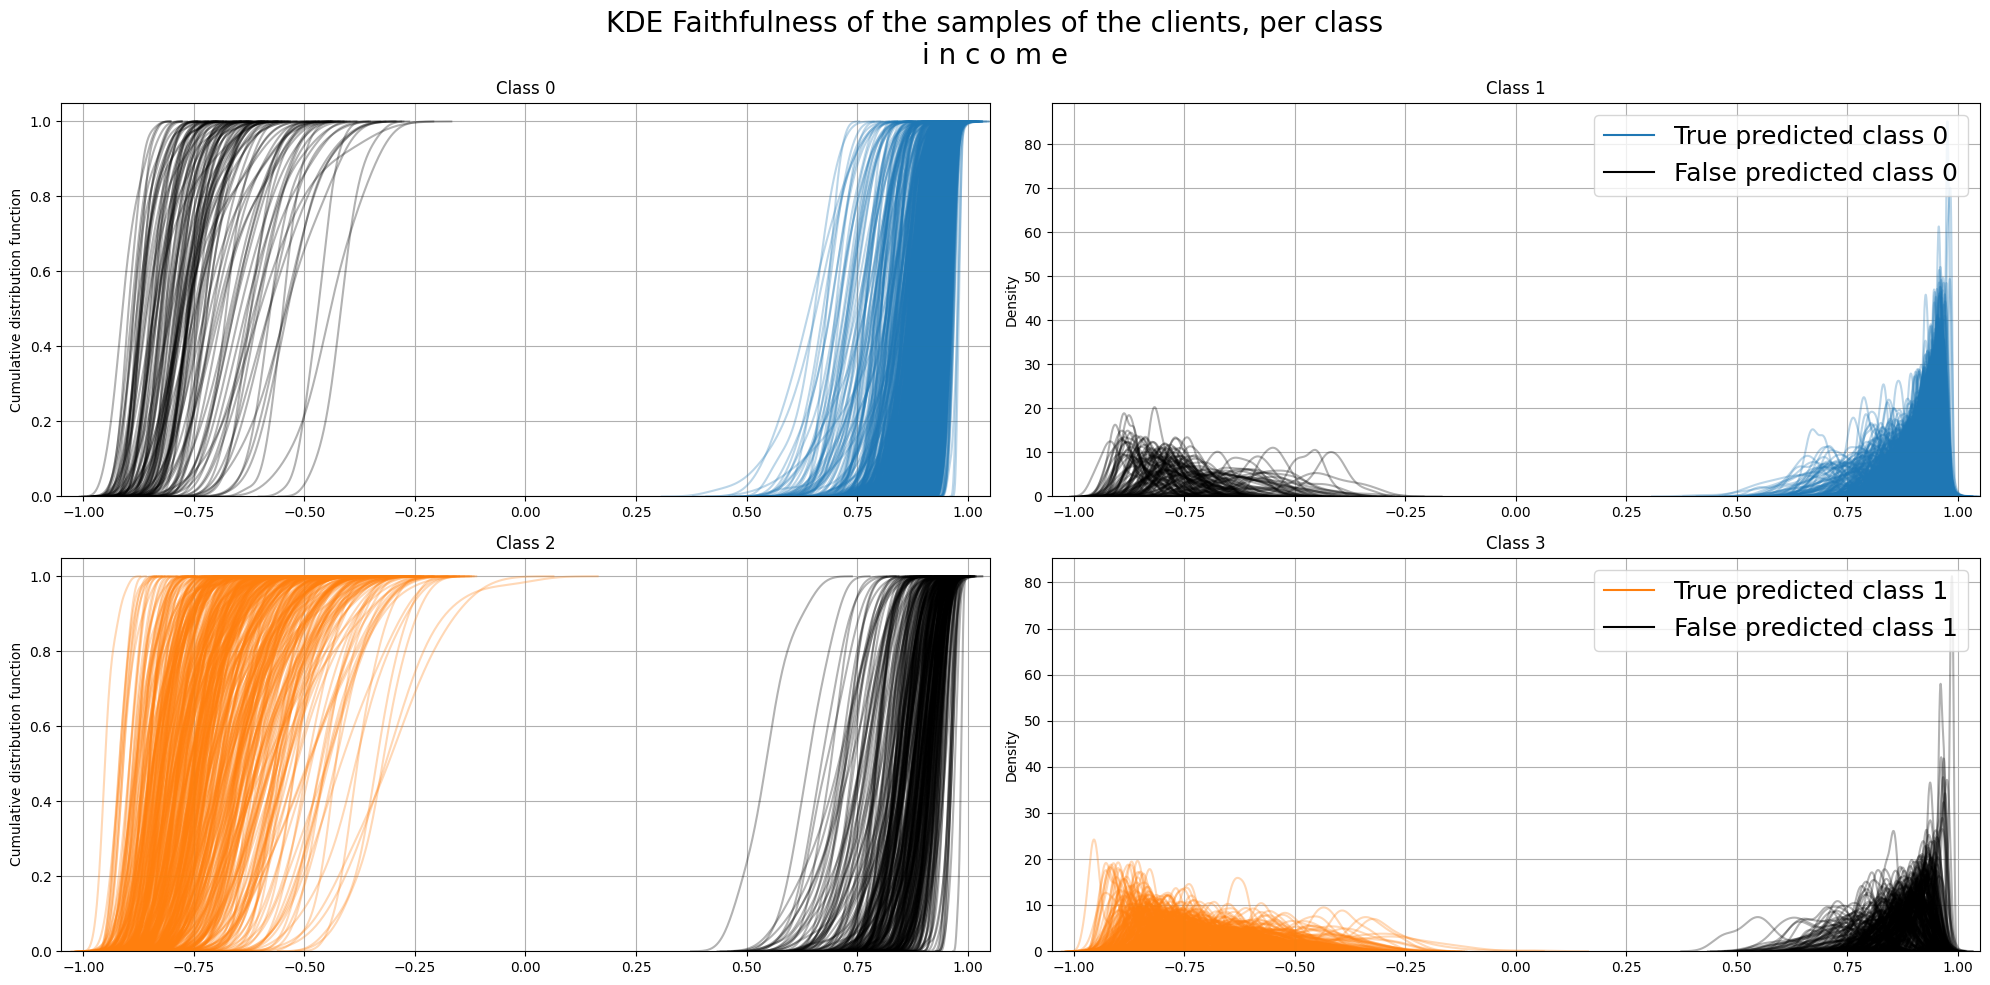

<Figure size 640x480 with 0 Axes>

In [104]:

indexes_per_calss_list.keys()#len(indexes_per_calss_list[exp])
indexes_per_calss_list2 = indexes_per_calss_list
for exp in focus:
    plt.clf()
    # plot the distributions of the faithfulness of every sample
    fig,ax = plt.subplots(len(indexes_per_calss_list2[exp]),2,figsize=(20,5*len(indexes_per_calss_list2[exp])))
    ax = ax.flatten()
    pred = activations_of_models[exp][0.001]
    for i,idxs in enumerate(indexes_per_calss_list2[exp]):
        color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
        ax[2*i+1].plot([0,0],[0,0],color=color,label="True predicted class "+str(i))
        ax[2*i+1].plot([0,0],[0,0],color='k',label="False predicted class "+str(i))
        for idx in idxs:
            # check if it it a true positive or a false positive
            if pred[idx].argmax() != i:
                color = 'k'
            else:
                color = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#7f7f7f','#bcbd22','#17becf'][i]
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i],cumulative=True)
            sns.kdeplot(all_faith_dict[exp][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.3,ax=ax[2*i+1],cumulative=False)
        # add a fake line for the legend
        


    old_y_lim = plt.ylim()
    # add fake lines for the legend

    plt.suptitle("KDE Faithfulness of the samples of the clients, per class\n"+" ".join([str(elemento) for elemento in exp]),fontsize=20)
    for j,axe in enumerate(ax.flatten()):
        axe.set_xlim(-1.05,1.05)
        axe.grid(True)
        axe.set_title("Class "+str(j))
        if j%2==1:
            axe.legend(fontsize=18, loc='upper right')
            axe.set_ylabel("Density")
        else:
            axe.set_ylabel("Cumulative distribution function")


    plt.ylim(old_y_lim)
    plt.savefig(dt_name+"_"+" ".join([str(elemento) for elemento in exp])+"_faithfulness_distributions.pdf")
    plt.tight_layout()
    plt.show()
    plt.close()
    plt.clf()



dict_keys(['Clients', 'Server']) (2,)


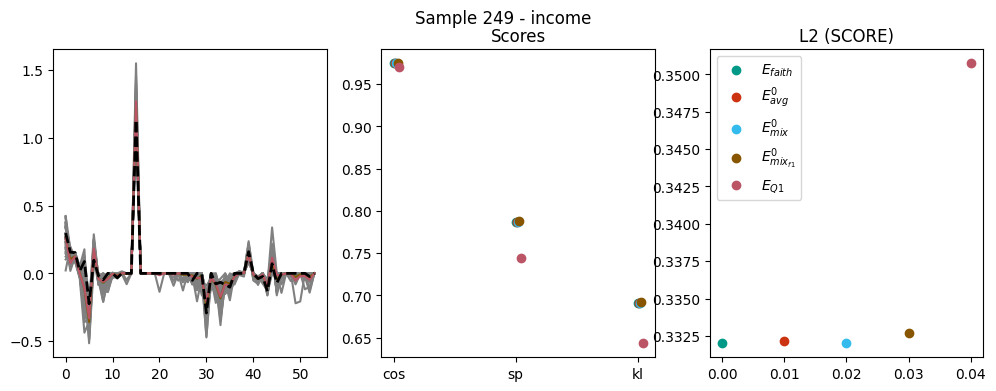

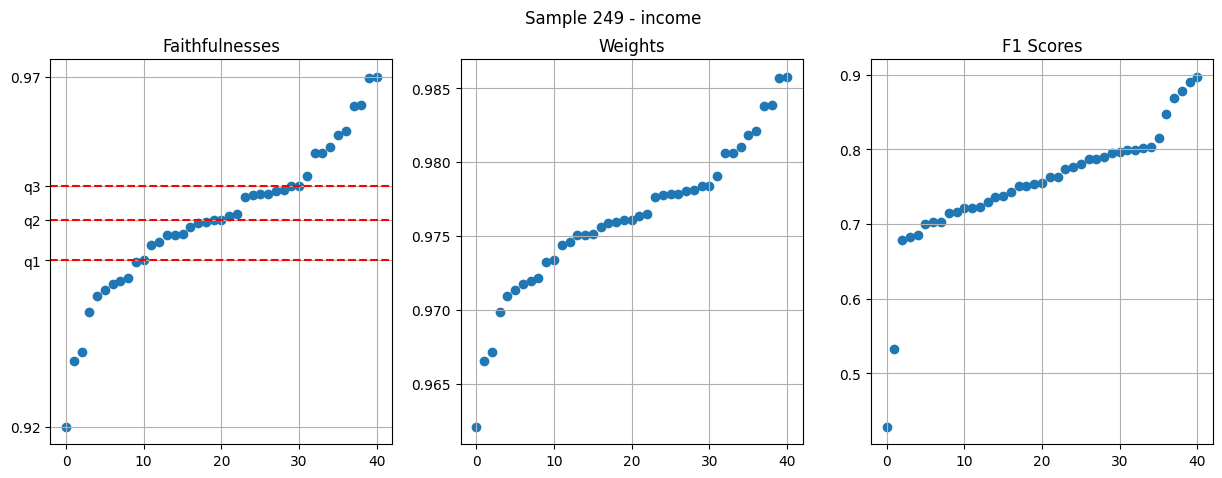

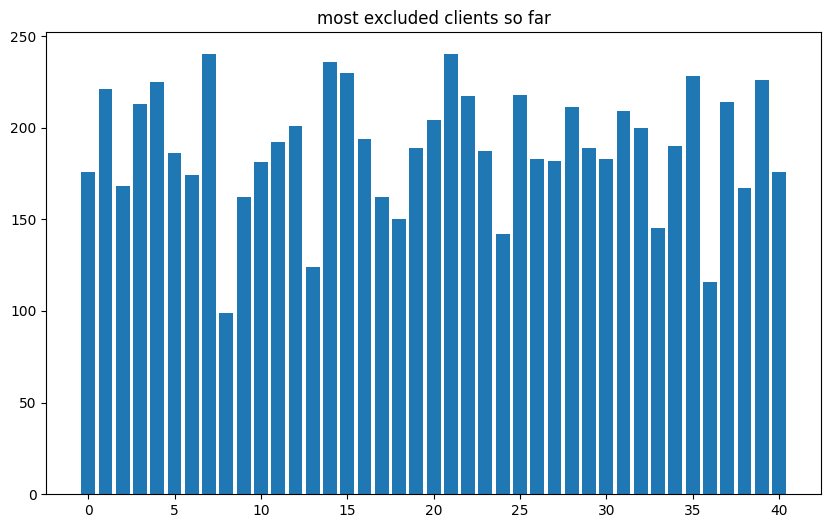

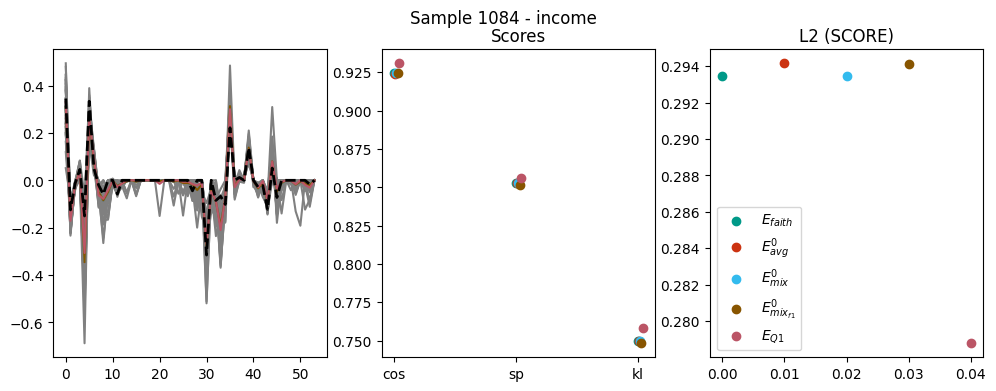

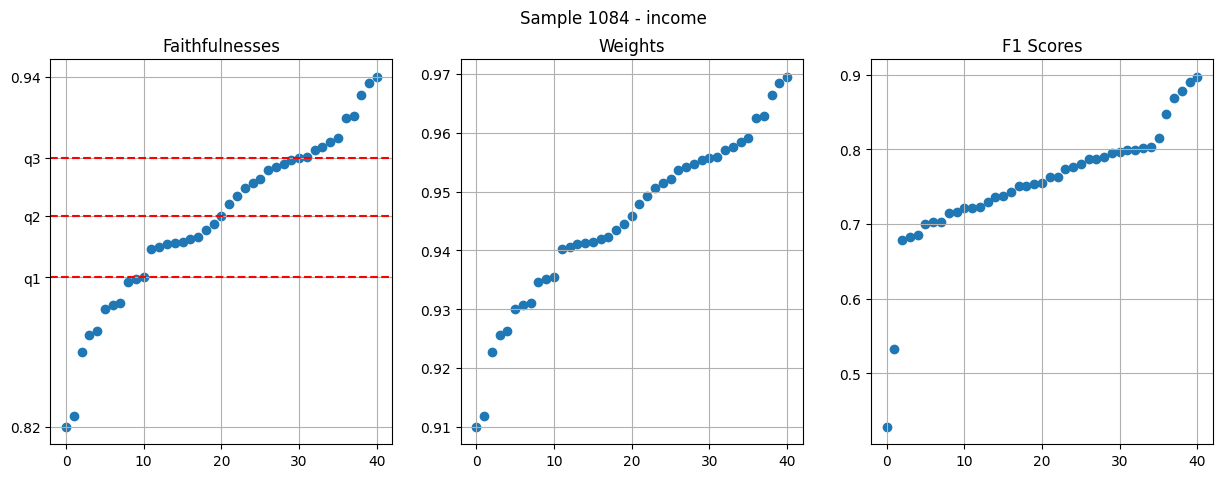

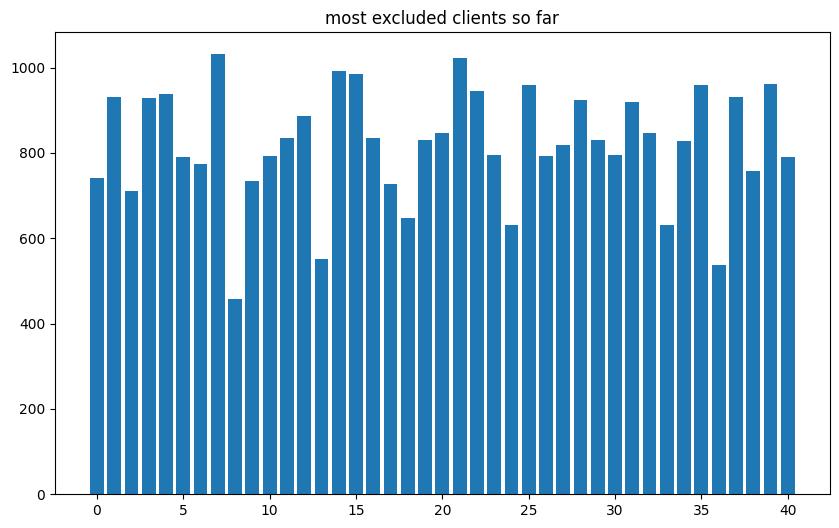

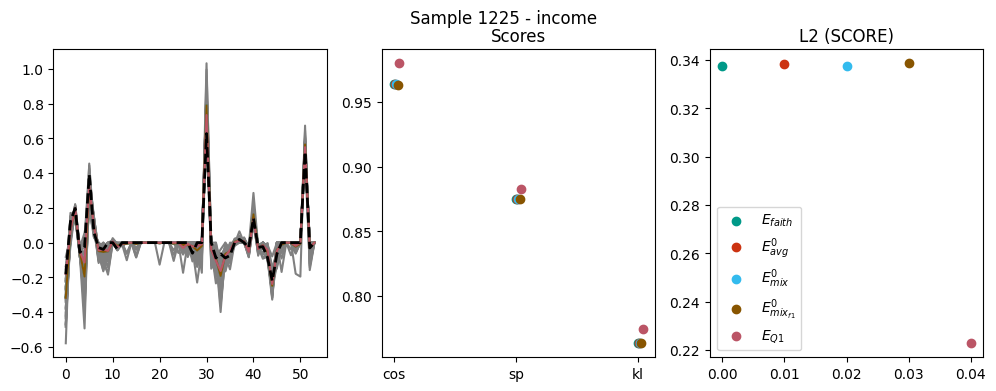

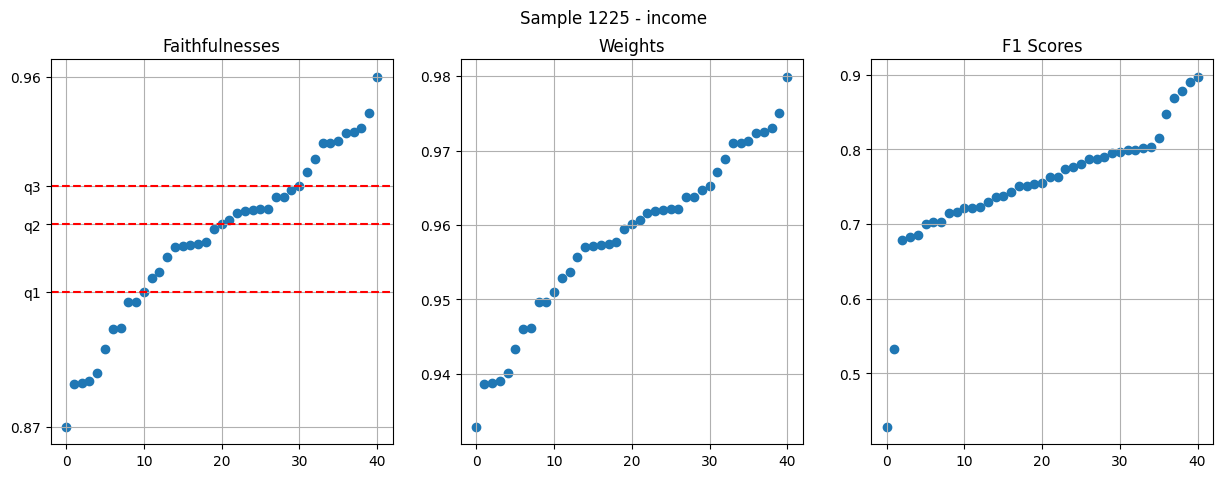

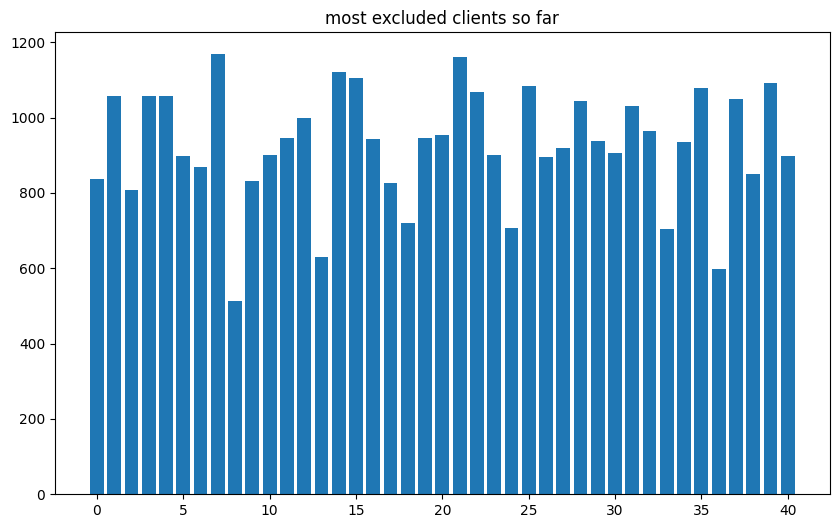

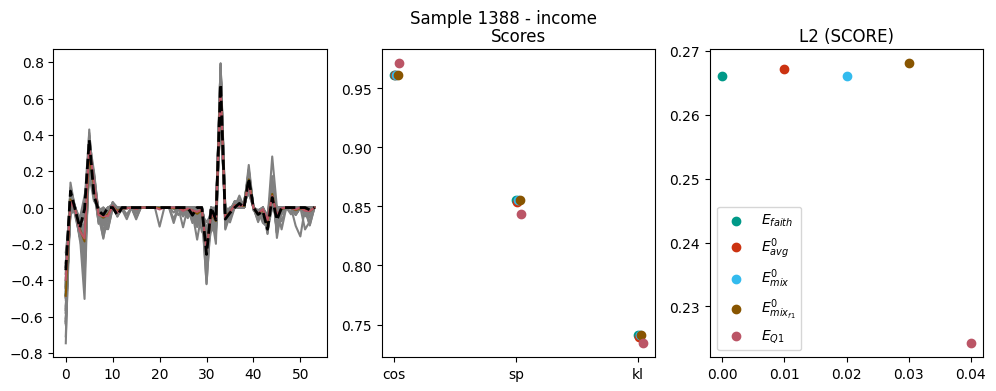

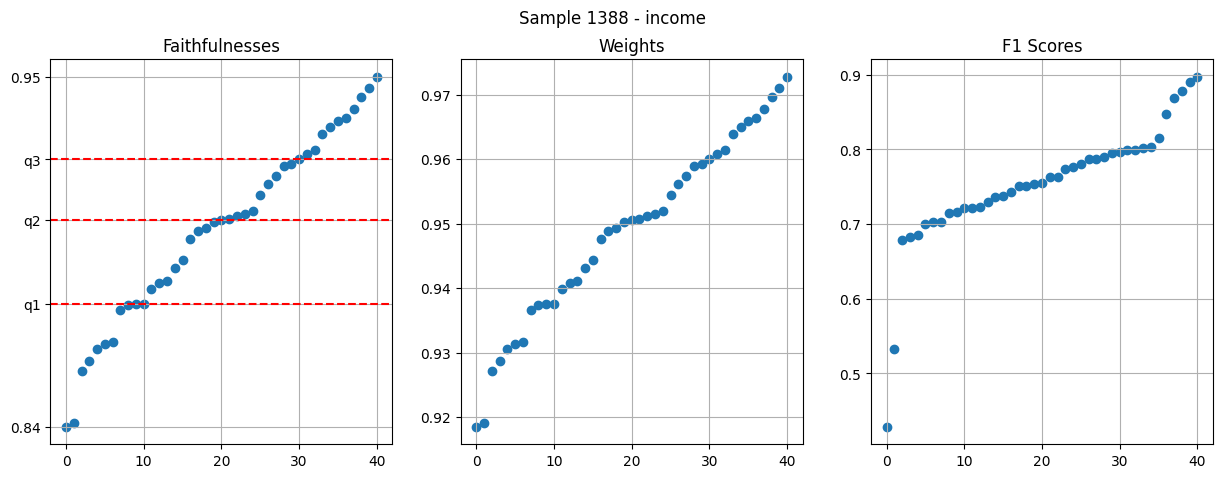

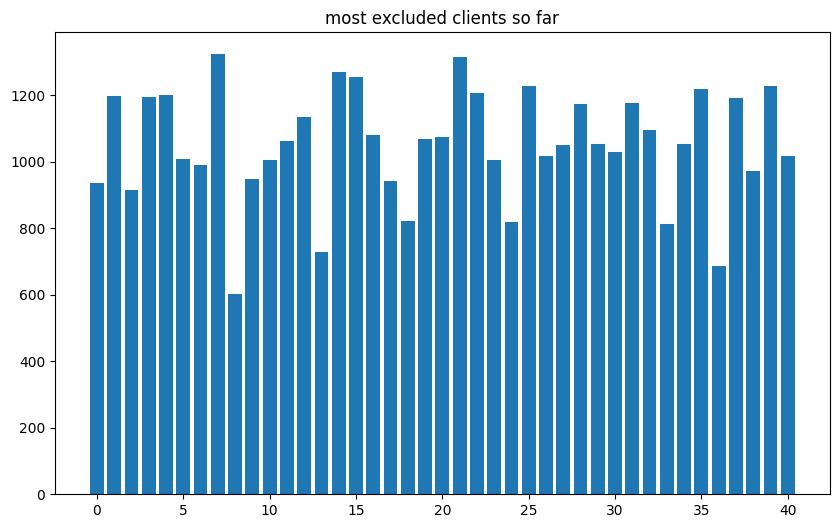

The explanations E_fait_weighted equal to the average are 0 over 2000 (0.0%)
The explanations E_avg_t_0 equal to the average are 1999 over 2000 (99.95%)
The explanations E_mixed equal to the average are 0 over 2000 (0.0%)
The explanations E_mix_f1 equal to the average are 0 over 2000 (0.0%)
The explanations E_Q1 equal to the average are 0 over 2000 (0.0%)
filter applied [1414] times
most excluded clients indexes: [[ 8 36 13 33 24 18  2  0 17  9 10 38  6  5 23 40 30 26 29 34 19 11 27 32
  16 20 12 28 31 37  1  4  3 22 25 39 35 15 14 21  7]]
[array([1332., 1716., 1291., 1722., 1718., 1436., 1430., 1896.,  862.,
       1365., 1421., 1530., 1647., 1083., 1838., 1815., 1561., 1341.,
       1197., 1523., 1568., 1875., 1740., 1442., 1191., 1741., 1481.,
       1532., 1686., 1502., 1474., 1699., 1559., 1191., 1507., 1771.,
       1005., 1703., 1423., 1766., 1460.])]


In [105]:
for exp in focus:
    print(all_faith_dict[exp][b_v].keys(),indexes_per_calss[exp].shape)
    policy_selection(exp = exp,
    faithfulnesses=all_faith_dict[exp][b_v],
    all_shap_values_dict=all_shap_dict,
    class_idxs = indexes_per_calss[exp],
    dt_name = "dutch",
    f1_scores=np.array([get_f1(exp,node,macro=True) for node in train_nodes]),
    show=(False if exp!=focus[0] else True))

In [106]:

props = [
        "E_hat",
        "E_weighted", # the explanation is the average of the explanations weighted by the f1 score
        "E_f1_macro", # the explanation is the average of the explanations weighted by the f1 score MACRO


        "E_fait_weighted", # the explanation is the average of the explanations weighted by the faithfulness
        "E_avg_t_0",       # the explanation is the average of the explanations filtered on the faithfulness > 0
                           # if there are not explanations that have 
        "E_mixed",         # 
        "E_mix_f1",
        "E_Q1",
        
        #"E_avg_t_06",
        #"E_france_W",
        #"E_harm",
        ]

In [107]:
# this function is used to compute the difference between the Explanation of the server and the different aggregations:
# it takes the name of the experiment and return the list of the name of the best aggregation
def sort_aggrg(exp,proposals = props):
    audit = "Server"
    diffs = []
    # compute the difference between the server and the aggregations
    for p in proposals:
        print(p)

        diff = compare_heatmaps_Frobenius(all_shap_dict[exp][audit],
                                all_shap_dict[exp][p]).mean()
        diffs.append(diff)
    # sort the aggregations by the difference
    return sorted(list(zip(proposals,diffs)),key=lambda x:x[1])
sort_aggrg(exp)

E_hat
E_weighted
E_f1_macro
E_fait_weighted
E_avg_t_0
E_mixed
E_mix_f1
E_Q1


[('E_weighted', 0.28412301462032225),
 ('E_mixed', 0.28469125421402636),
 ('E_hat', 0.28479930766182415),
 ('E_avg_t_0', 0.28494323734108645),
 ('E_f1_macro', 0.2854617470269129),
 ('E_mix_f1', 0.285605205479747),
 ('E_fait_weighted', 0.288262693109971),
 ('E_Q1', 0.2925778612806306)]

In [91]:
# QUIQUOQUAo

In [108]:
dt_name='adult'

In [109]:
folder


'income'

CosSim <function compare_heatmaps_cosinesim at 0x7fd7d6ab15e0>
Spearman <function compare_heatmaps_spearmanr at 0x7fd7d6ab1550>
Frobenius <function compare_heatmaps_Frobenius at 0x7fd7d6ab1790>


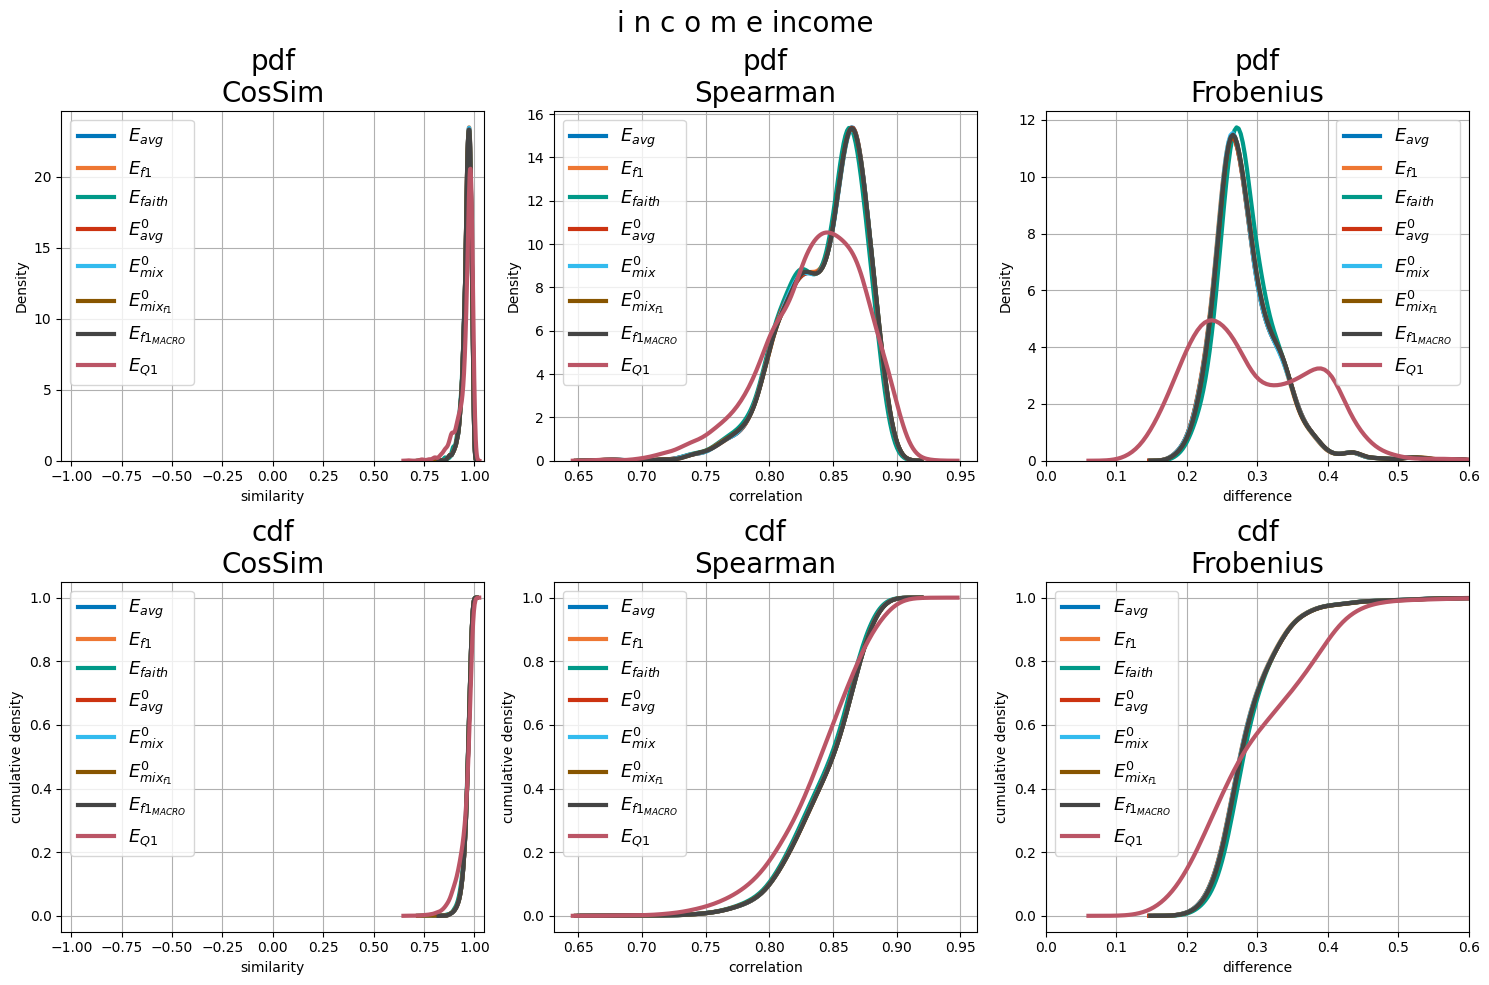

In [95]:
new_colors = {k:v for k,v in colors.items() if k in 
                  props}
f = plot_desity_comparisons_functions(exp=folder,all_shap_values_dict=all_shap_dict,
                                    activations_of_models=activations_of_models,

                                    colors=new_colors, show=True,vmax =0.6,dt_name = folder)

In [124]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)
colors

{'E_hat': '#0077BB',
 'E_weighted': '#EE7733',
 'E_fait_weighted': '#009988',
 'E_avg_t_0': '#CC3311',
 'E_mixed': '#33BBEE',
 'E_mix_f1': '#885500',
 'E_avg_t_06': '#DDAA33',
 'E_f1_macro': '#444444',
 'E_france_W': '#004488',
 'E_Q1': '#BB5566',
 'Server': '#000000'}

In [126]:
all_kendals_frobs = {}
# test the function
for exp in focus:#["016_imb_0.99"]:
    k,f,cs,sprmn,d,single_k,single_f,single_cs,single_sprmn = plot_global_and_differencies(exp=folder,
                                                                        all_shap_values_dict = all_shap_dict,
                                                                        activations_of_models = activations_of_models,
                                                                        proposals=props,
                                                                        feat_names=feat_names,
                                                                        indices=indexes_per_calss[exp],
                                                                        dt_name = dt_name,
                                                                        selection=props,
                                                                        show=False)
    all_kendals_frobs[exp] = (k,f,cs,sprmn,d,single_k,single_f,single_cs,single_sprmn)
    # _differences_global_explanation.pdf,
    # _global_explanation_by_class.pdf,
    # _global_explanation.pdf
    
    print(exp)

dict_keys(['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'])
kendalltau's have 8 elements, and shape  (2,)
diff has  8 elements, and shape  (2,)
shap_CS has  8 elements, and shape  (2,)
spearmanss has  8 elements, and shape  (2,)
the max and min of the global explanation are 0.23525985585955209 -0.04574092377458745
the max and min of the global explanation are 0.05210856966552758 -0.3523109065747213
(8, 54)
(8, 54)
putting tight layout
saved the figure adult_income_global_explanation_by_class.pdf
saved the figure adult_income_global_explanation_by_class.png
1 2
2
saved the figure adult_income_global_explanation_by_class_E_hat.pdf
saved the figure adult_income_global_explanation_by_class_E_hat.png
1 2
2
saved the figure adult_income_global_explanation_by_class_E_weighted.pdf
saved the figure adult_income_global_explanation_by_class_E_weighted.png
1 2
2
saved the figure adult_income_global_explanation_by_cla

Glyph 12 () missing from current font.
Glyph 12 () missing from current font.
Glyph 12 () missing from current font.


income


<Figure size 640x480 with 0 Axes>

In [98]:
dt_name

'adult'

In [216]:
# for every experiment, recompute the faithfulness of the aggregation methods.
# to see if there is an increase in faithfulness 

all_faith_dict_recomputed = {}
for exp in focus:
    print(exp,end='\t')
    all_faith_dict_recomputed[exp] = {}
    _,updated_fait_dict,_ = recalculate_faiths(neural_model=model,
                                               exp=folder,
                                               all_shap_values_dict = all_shap_dict,
                                               base_value = all_base_values[exp][b_v],
                                               te_set = exp_dt,
                                               proposals=props+["Server"])
    print(updated_fait_dict.keys())
    all_faith_dict_recomputed[exp][b_v] = {p:np.array(updated_fait_dict[p]) for p in updated_fait_dict.keys()}




plt.show()

income	(2000, 2)


The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)


dict_keys(['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server'])


In [226]:
focus

['income']

In [229]:
# plot the recalculated faithfulness values as a latex table 1 colum for each aggregation method
# one raw for each experiment
# the first column is the name of the dataset, the second is the # of clients the third is the distribution
# from the fourth on, we have the faithfulness values mean and std of the faithfulness values of the aggregations
# and the server

for exp in focus:    
    
    vals = [all_faith_dict_recomputed[exp][b_v][p] for p in props+["Server"]]
    print(props+["Server"])
    row = " & ".join(["Income"]+[f"{v.mean():.2f}±{v.std():.2f}" for v in vals])
    print(row)
    

['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1', 'Server']
Income & 0.31±0.61 & 0.31±0.61 & 0.31±0.61 & 0.31±0.61 & 0.31±0.61 & 0.31±0.61 & 0.31±0.61 & 0.29±0.63 & 0.31±0.53


9 recalculated faiths (2 are for the Server, and the Clients)
(2000, 9)
Server	plotted; (1, 2000)		black
E_hat	plotted; (1, 2000)		#0077BB
E_weighted	plotted; (1, 2000)		#EE7733
E_f1_macro	plotted; (1, 2000)		#444444
E_fait_weighted	plotted; (1, 2000)		#009988
E_avg_t_0	plotted; (1, 2000)		#CC3311
E_mixed	plotted; (1, 2000)		#33BBEE
E_mix_f1	plotted; (1, 2000)		#885500
E_Q1	plotted; (1, 2000)		#BB5566


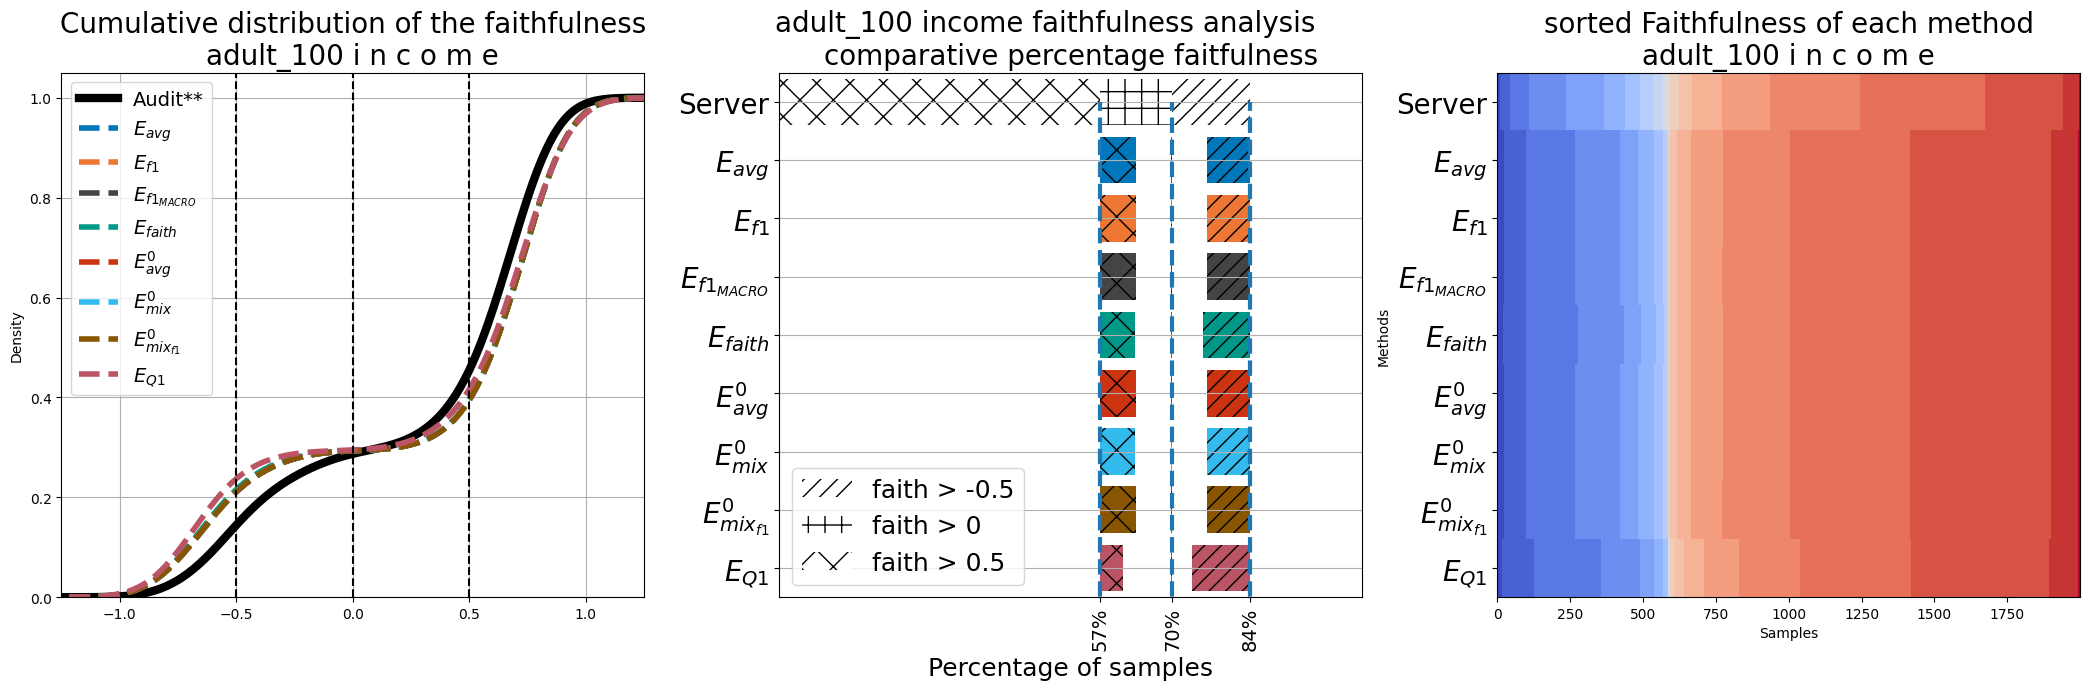

In [217]:
plot_recalulated_faiths(exp =folder,
                        faiths = all_faith_dict_recomputed,
                        base_value = b_v,
                        proposals = props,
                        dt_name=dt_name,
                        show=True)

In [218]:
metriche = ["$ShapGap_{Kendall}$","$ShapGap_{L2}$","$ShapGap_{CosSim}$","$ShapGap_{Spearman}$"]
metric_functions = [compare_heatmaps_kendalltau,
                    compare_heatmaps_Frobenius,
                    compare_heatmaps_cosinesim,
                    compare_heatmaps_spearmanr]

In [219]:
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1']

In [220]:
import importlib
import iflash as flx
from iflash import *
#
importlib.reload(flx)

In [221]:
for exp in focus:
    # now we want to produce the cd diagrams for the faithfulness values as well, for the same aggregations and the server
    # as "metric" we use the faithfulness values
    # as for the metric functions, the higher the value the better
    # so we do not need to flip the values
    all_faith_dict_list = all_faith_dict_recomputed[exp][b_v]
    
    values = np.array([all_faith_dict_list[p].reshape(-1) for p in props+["Server"]])
    values = values.T
    metr = "Faithfulness"
    print(exp)
    current_title = exp
    current_title+="\n"+metr+"\n"
    create_df_and_check(methods_names=props+["Server"],
                        values=values,
                        title=current_title,
                        show = False,
                        exp = exp,
                        metrica=metr,
                        dt_name=dt_name,
                        vmin=-1.025,vmax=1.025)

income
{'$E_{avg}$': '#0077BB', '$E_{f1}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{MACRO}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000'} res_colors
Index(['$E_{avg}$', '$E_{f1}$', '$E_{f1_{MACRO}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$',
       'Audit**'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1}$  $E_{f1_{MACRO}}$  $E_{faith}$  \
$E_{avg}$               1.0       0.0               0.9          0.0   
$E_{f1}$                0.0       1.0               0.0          0.0   
$E_{f1_{MACRO}}$        0.9       0.0               1.0          0.0   
$E_{faith}$             0.0       0.0               0.0          1.0   
$E_{avg}^{0}$           0.9       0.0               0.9          0.0   
$E_{mix}^{0}$         

In [222]:
SHOWW = False
valueminmax = [(.59,1.0)]# kendall
valueminmax+= [(0.1,0.8)]# frobenius
valueminmax+= [(0.85,1.025)]# cosine sim
valueminmax+= [(0.6,1.025)]# spearman
for metr,metr_f,(vm,vM) in zip(metriche,metric_functions,valueminmax):
        values = []
        print(metr)
        
        for p in props:
            print(p)
            vals = metr_f(all_shap_dict[exp]["Server"],all_shap_dict[exp][p])
            if metr != "$ShapGap_{L2}$":
                # we multiply the values for -1 because the Frobenius distance is a distance, so the higher the value the worse
                print("flipped",metr)
                vals *=-1
            values.append(vals)
        values = np.array(values)
        print(values.shape)
        create_df_and_check(methods_names=props,
                            values=values.T,
                            title=exp+"\n"+metr+" ",
                            show=SHOWW,
                            exp=folder,
                            metrica=metr,
                            dt_name = dt_name,
                            vmin=vm,vmax=vM)

$ShapGap_{Kendall}$
E_hat
flipped $ShapGap_{Kendall}$
E_weighted
flipped $ShapGap_{Kendall}$
E_f1_macro
flipped $ShapGap_{Kendall}$
E_fait_weighted
flipped $ShapGap_{Kendall}$
E_avg_t_0
flipped $ShapGap_{Kendall}$
E_mixed
flipped $ShapGap_{Kendall}$
E_mix_f1
flipped $ShapGap_{Kendall}$
E_Q1
flipped $ShapGap_{Kendall}$
(8, 2000)
{'$E_{avg}$': '#0077BB', '$E_{f1}$': '#EE7733', '$E_{faith}$': '#009988', '$E_{avg}^{0}$': '#CC3311', '$E_{mix}^{0}$': '#33BBEE', '$E_{mix_{f1}}^0$': '#885500', '$E_{avg}^{-0.6}$': '#DDAA33', '$E_{f1_{MACRO}}$': '#444444', '$E_{faith}^{-0.6}$': '#004488', '$E_{Q1}$': '#BB5566', 'Audit**': '#000000'} res_colors
Index(['$E_{avg}$', '$E_{f1}$', '$E_{f1_{MACRO}}$', '$E_{faith}$',
       '$E_{avg}^{0}$', '$E_{mix}^{0}$', '$E_{mix_{f1}}^0$', '$E_{Q1}$'],
      dtype='object') columns of the ranking_df
plotting CD diagram
                  $E_{avg}$  $E_{f1}$  $E_{f1_{MACRO}}$  $E_{faith}$  \
$E_{avg}$              1.00      0.44              0.23          0.0   
$E_{f

In [127]:
dt_name

'adult'

In [129]:
# now save all the all_shap_values_dict converting the numpy arrays to lists
json.dump({k: {k2: np.array(v2).tolist() for k2, v2 in vv.items()} for k, vv in all_shap_dict.items()}
    ,open(dt_name+"_all_shap_values_dict_new.json","w+"))

unclosed file <_io.TextIOWrapper name='adult_all_shap_values_dict_new.json' mode='w+' encoding='UTF-8'>


In [130]:

with open(dt_name+"_all_shap_values_dict_new.json", "r") as f:
    loaded_dict = json.load(f)

all_shap_values_dict_loaded = {k: {k2: np.array(v2) for k2, v2 in v.items()} for k, v in loaded_dict.items()}

NameError: name 'all_faith_dict_recomputed' is not defined

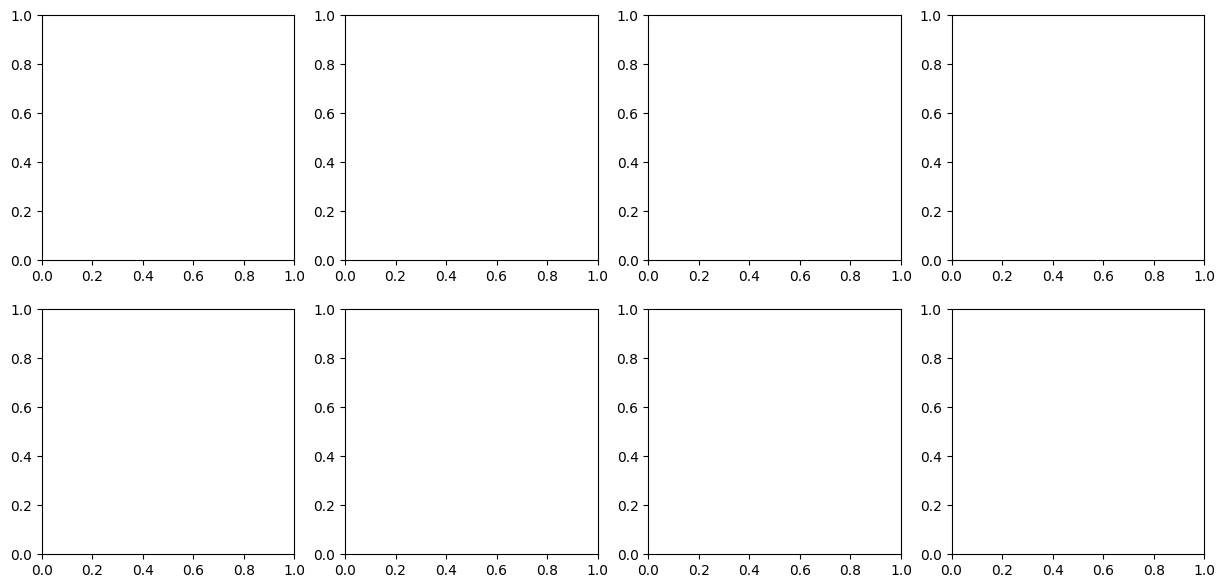

In [131]:

# i want to plot now a thing. let's start by producing a scattering plot of the faithfulness values of the samples and the L2 norm of the explanations
for exp in focus:
    fix,ax = plt.subplots(2,4,figsize=(15,7))
    ax=ax.flatten()
    # add all the faithfulness values of the samples and the L2 norms of the explanations per aggregation
    data_d = {}
    for j,p in enumerate(props):
        data_d[p] = {"faithfulness":np.array(all_faith_dict_recomputed[exp][b_v][p]).flatten(),
                     "L2":compare_heatmaps_Frobenius(all_shap_values_dict_loaded[exp]["Server"],all_shap_values_dict_loaded[exp][p])}

    for j,p in enumerate(props):        
        data = pd.DataFrame(data_d[p])    
        for jj,axe in enumerate(ax):
            sns.kdeplot(data=data,x="faithfulness",y="L2",ax=axe,fill=False,color="grey",label='',alpha=0.2)

        ax[j].set_title(res_d[p],fontsize=15)
        ax[j].set_xlabel("faithfulness")
        ax[j].set_ylabel("$ShapGap_{L2}$")
        #ax[j].set_xlim(-1.15,1.35)
    for j,p in enumerate(props):
        data = pd.DataFrame(data_d[p])
        sns.kdeplot(data=data,x="faithfulness",y="L2",label=p,ax=ax[j],fill=True,color=colors[p])
        # scatter plot the faithfulness values of the samples and the L2 norm of the explanations
        ax[j].scatter(data["faithfulness"],data["L2"],label=p,c=colors[p],alpha=0.5,s=5,marker=".")
        ylim = ax[j].get_ylim()
        ax[j].set_ylim(0.095,0.6)
    # in the last plot we plot the faithfulness values of the samples and the L2 norm of the explanations of the server
    # the L2 is trivially 0, so we plot only the faithfulness kde values, without a 1d kde plot
    # sns.kdeplot(all_faith_dict_recomputed[exp][b_v]["Server"][0],fill=True,label="",ax=ax[-1],color=colors["Server"])
    #ax[-1].set_title("Server")
    # remove the y ticks from the last plot
    #ax[-1].set_yticks([])
    plt.suptitle(dt_name+" "+"\nfaithfulness vs $ShapGap_{L2}$",fontsize=15)
    plt.tight_layout()
    plt.savefig(dt_name+"_"+exp+"_faithfulness_vs_L2.pdf")
    plt.show()
    
    # create the dataframe
    # create the scatter plot

In [225]:
b_v,all_base_values[exp]

(1000,
 {1000: tensor([0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286,
          0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286,
          0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286,
          0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286,
          0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286,
          0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286, 0.1286],
         dtype=torch.float64),
  100: tensor([3.4073e-01, 4.4305e-01, 1.4483e-01, 1.2564e-01, 3.5388e-01, 5.3445e-01,
          5.8902e-01, 4.2774e-02, 6.2066e-02, 1.4894e-01, 2.6568e-02, 1.0021e-01,
          2.8993e-02, 1.4331e-03, 0.0000e+00, 5.6223e-03, 3.3072e-04, 1.1024e-04,
          3.3072e-04, 3.3072e-04, 2.2048e-03, 2.3151e-03, 2.9765e-03, 6.1735e-03,
          5.9530e-03, 8.1579e-03, 1.6867e-02, 6.9452e-03, 1.1686e-02, 5.9530e-03,
          2.3272e-01, 2.0174e-02, 2.2599e-02, 1.

In [125]:
(all_faith_dict[folder][b_v]["Server"]>-0.5).sum()/2000

0.8485

['C1', 'C12', 'C6', 'C7', 'C21', 'C14', 'C41', 'C39', 'C20', 'C15', 'C26', 'C30', 'C11', 'C23', 'C37', 'C22', 'C31', 'C32', 'C36', 'C10', 'C35', 'C29', 'C2', 'C33', 'C3', 'C38', 'C4', 'C17', 'C5', 'C8', 'C18', 'C9', 'C13', 'C40', 'C25', 'C24', 'C27', 'C19', 'C34', 'C28', 'C16']
['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1']
[(2000, 54), (2000, 54), (2000, 54), (2000, 54), (2000, 54), (2000, 54), (2000, 54), (2000, 54)]


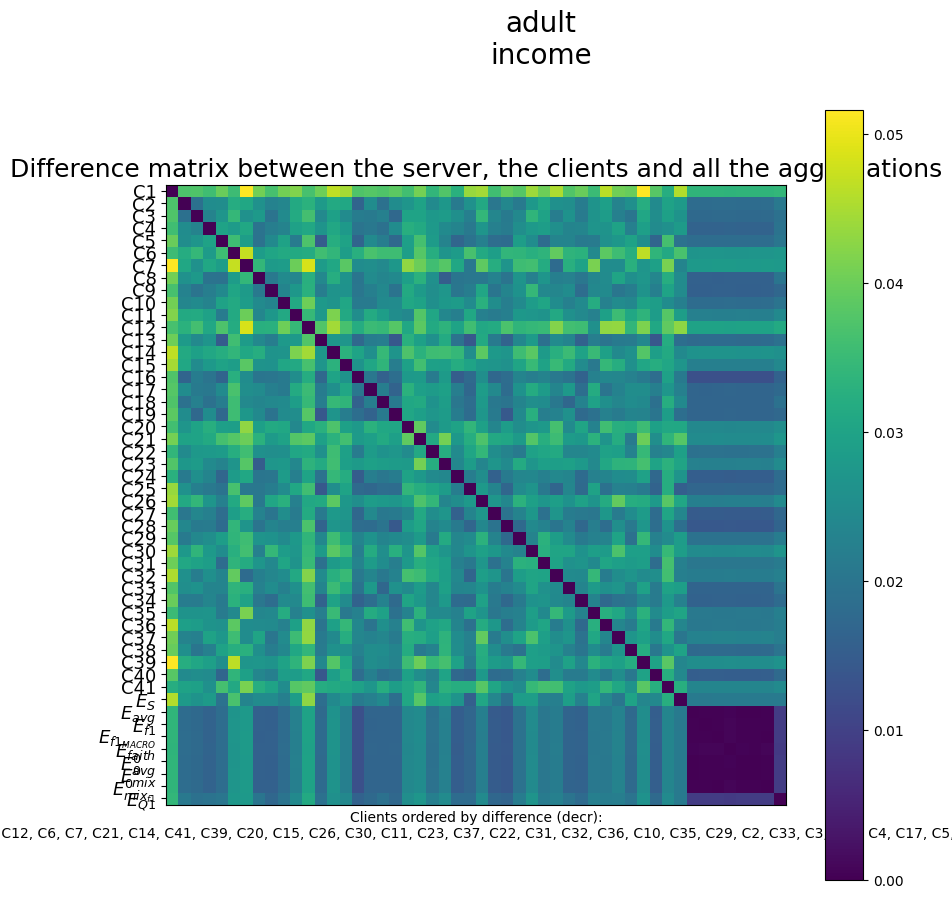

<Figure size 640x480 with 0 Axes>

In [125]:
fig,ax = plt.subplots(1,1,figsize=(10,10))
plot_differences(dictionary = all_shap_dict[folder],
                proposals=props,
                axes=ax,
                colorbar = True)
plt.suptitle(dt_name+"\n"+folder,fontsize=20)
ax = plt.gca()
ax.set_title("Difference matrix between the server, the clients and all the aggregations",fontsize=18)
plt.savefig(dt_name+"_"+folder+"_difference_matrix.pdf")
plt.show()
plt.close()
plt.clf()

In [127]:
# use the PDF merger to merge the CD plots
import PyPDF2
import os
merger = PyPDF2.PdfMerger()
pdfs = [el for el in os.listdir() if "CD_$" in el and "pdf" in el and dt_name in el]
pdfs_found = sorted([p[::-1] for p in pdfs])
assert len(pdfs_found) == 3,"not all the plots have been found"+str(pdfs_found)
# sort them so that the order is L2, CosSim and Kendall
pdfs = [None]*3
pdfs[0] = [p for p in pdfs_found if "{L2}" in p][0]
pdfs[1] = [p for p in pdfs_found if "{CosSim}" in p][0]
pdfs[2] = [p for p in pdfs_found if "{Kendall}" in p][0]
print(pdfs)
for e in pdfs:
    print(e)
    merger.append(e[::-1])  
    print(e[::-1])
merger.write(dt_name+"_CD_plots.pdf")
print("file saved at",dt_name+"_CD_plots.pdf")

PyPDF2 is deprecated. Please move to the pypdf library instead.


IndexError: list index out of range

In [146]:
dt_name+"_CD_plots.pdf"

'adult_CD_plots.pdf'

In [135]:
len(indexes_per_calss_list[folder])

2

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


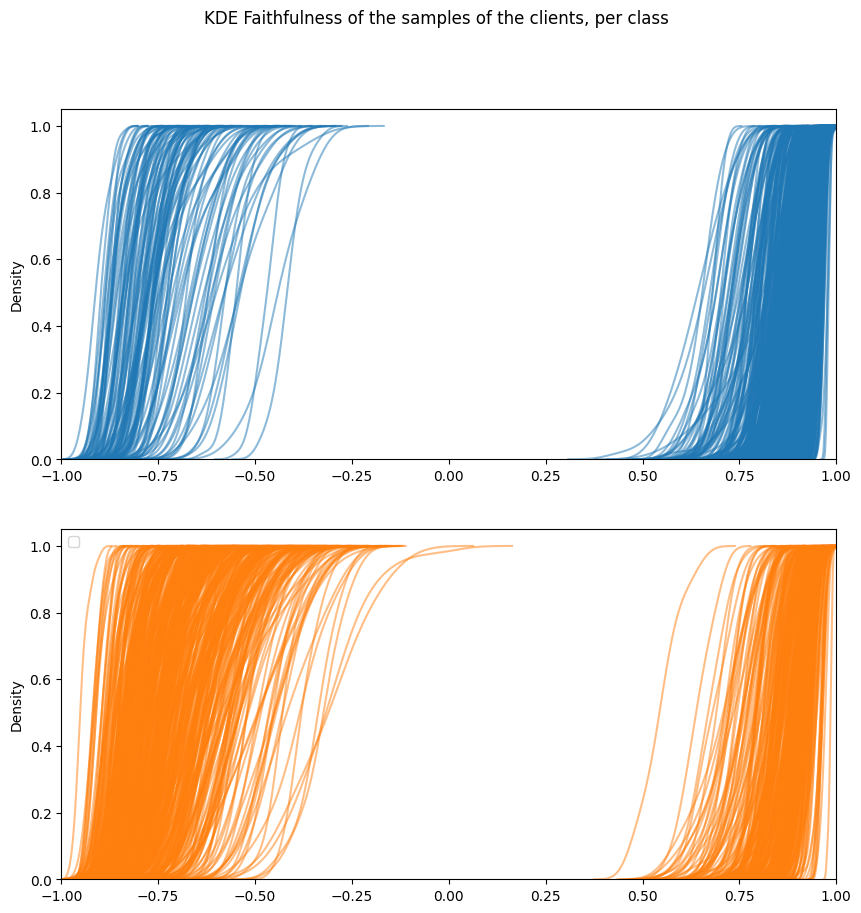

In [215]:
# plot the distributions of the faithfulness of every sample
fig,ax = plt.subplots(len(indexes_per_calss_list[folder]),1,figsize=(10,5*len(indexes_per_calss_list[folder])))

for i,idxs in enumerate(indexes_per_calss_list[folder]):
    color = ['#1f77b4','#ff7f0e'][i]
    for idx in idxs:
        sns.kdeplot(all_faith_dict[folder][b_v]["Clients"].T[idx].flatten(),color = color,alpha=0.5,ax=ax[i],cumulative=True)


old_y_lim = plt.ylim()
# add fake lines for the legend

plt.suptitle("KDE Faithfulness of the samples of the clients, per class")
plt.legend()
for axe in ax.flatten():
    axe.set_xlim(-1,1)

plt.ylim(old_y_lim)
plt.show()

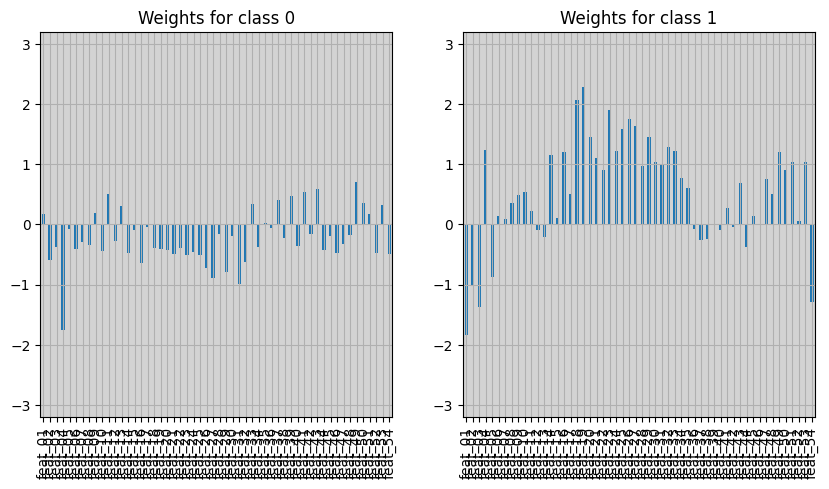

In [137]:
# now plot the model.layer1.weights as histograms
# the bars should be placed on 2 subplots with the same y axis
df = pd.DataFrame(model.layer1.weight.detach().numpy(),columns=feat_names)
fig,ax = plt.subplots(1,2,figsize=(10,5))
df.loc[0].plot(kind='bar',ax=ax[0],alpha=1,stacked=False)
ax[0].set_title("Weights for class 0")
df.loc[1].plot(kind='bar',ax=ax[1],alpha=1,stacked=False)
ax[1].set_title("Weights for class 1")
for a in ax:
    a.set_facecolor('lightgray')
    a.grid(True)
    # set y lim
    a.set_ylim(-3.2,3.2)
    
plt.show()

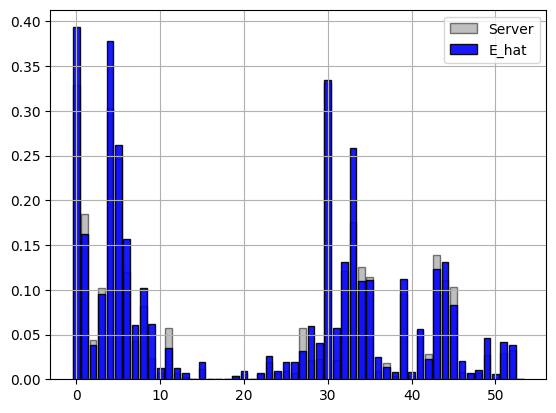

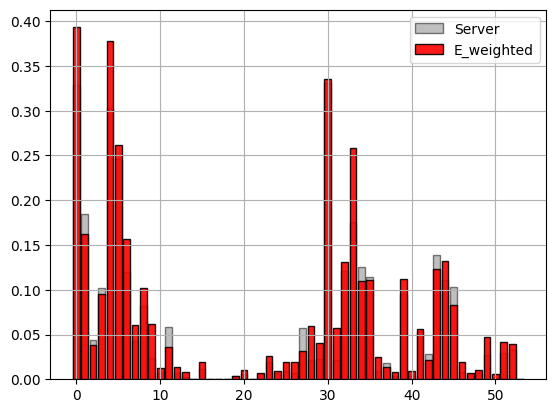

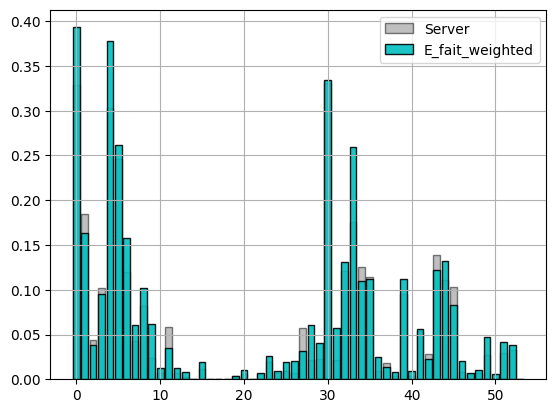

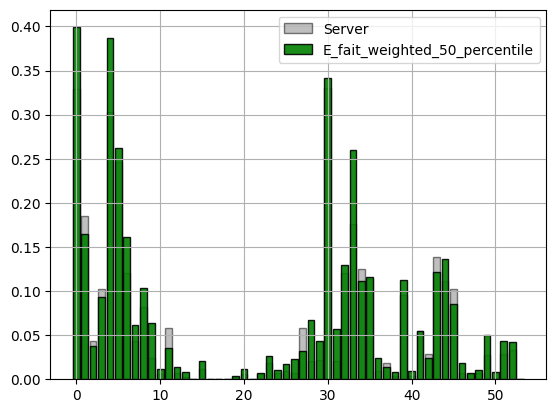

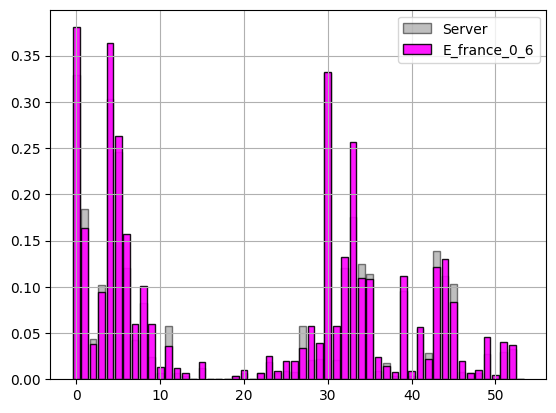

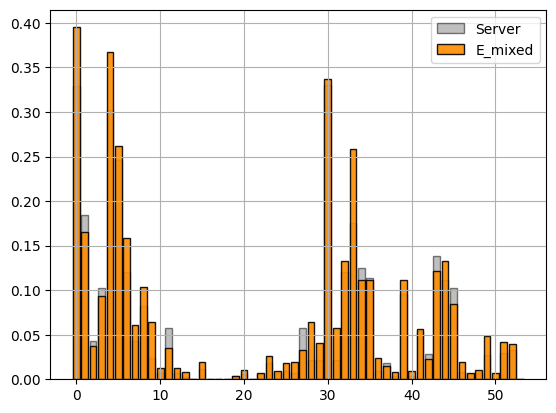

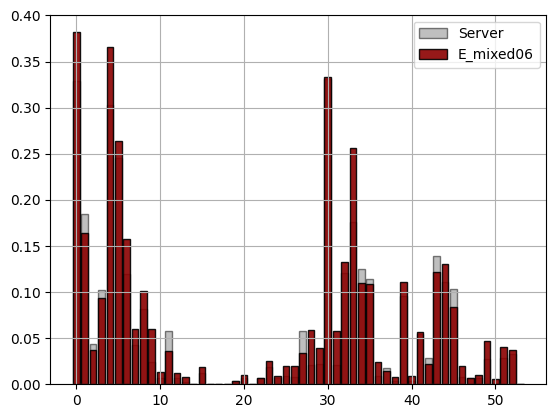

In [166]:
for p in props:
    plt.bar(np.arange(54),np.abs(all_shap_dict[folder]["Server"]).mean(0),label="Server",alpha=0.5,edgecolor='black',
                color="grey")
    plt.bar(np.arange(54),np.abs(all_shap_dict[folder][p]).mean(0),label=p,alpha=0.9,edgecolor='black',
            color=colors[p] if p!="Server" else "black")
    plt.grid(True)
    plt.legend()
    plt.show()